# DSC 180A PA5: Expand labels, rerun FastText, explaining the change from PA4 to PA5 (Kerim)

This PA builds on `Kerim_Orucevic_PA4_FastText.ipynb` from PA4, (100 labels to train, account and time split, 5-epoch's in FastText) and follows

**Two parts with a human review between them**

- **Part 1** (run top to bottom): pulls 900 new memos from the *same accounts* as `labels_kerim.csv`, freezes the
  split, writes AI label suggestions, and opens a review loop.
- **Human review**: you accept / correct / mark unresolved each AI/FastText suggestion (`review_loop()`).
- **Part 2**: builds `labels_v2.csv` (about 1,000 labels), reruns FastText with the Week 5 lecture's experiment plan.

The real data stays on DataHub: everything here runs locally — no single memo leaves the data server.

### 1.1. Setup and expanding label set

In [8]:
import re, os, gc, json, time, glob, math, hashlib, platform, random
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt
import fasttext
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from IPython.display import display, clear_output

pd.set_option("display.max_colwidth", 110)
try:
    pa.jemalloc_set_decay_ms(0)
except Exception:
    pass

DATA_DIR    = "/home/korucevic/teams/d12/UCSD - Data Share"
LABELS_PATH = Path("/home/korucevic/teams/d12/kerim_lecture3/labels/labels_kerim.csv")  
PA4_DIR     = Path("/home/korucevic/teams/d12/kerim_pa4")
PA4_MODEL   = PA4_DIR / "memo_fasttext_5ep.bin"
OUT_DIR     = Path("/home/korucevic/teams/d12/kerim_pa5")
SEED        = 0

N_NEW          = 900                                  
BUCKET_TARGETS = {"train": 585, "val": 135, "test_A": 90, "test_B": 90}   
TEAM_VAL_START, TEAM_TEST_START = "2026-04-01", "2026-06-01"       
HELDOUT_ACCOUNT_SHARE = 0.20      
SPARSE_TARGET  = 25               
N_GENERAL      = 1_000_000        

AUDIT_FRACTION, AUDIT_MIN, AUDIT_MAX_ERROR = 0.25, 30, 0.05  
MAX_ACCEPTED_ERROR = 0.05         

FT_THREAD = 1                     
BUCKET    = 2_000_000             
PA4_PARAMS = dict(epoch=5, wordNgrams=2, minn=3, maxn=6)              
OUT_DIR.mkdir(parents=True, exist_ok=True)
REVIEW_PATH = OUT_DIR / "review_batch.csv"
ALL_PARTS = sorted(glob.glob(f"{DATA_DIR}/ucsd_transactions_part_*.parquet"))
SCHEMA = pq.ParquetFile(ALL_PARTS[0]).schema_arrow
DIR_COL = next((c for c in ["credit_or_debit", "direction", "debit_credit", "cr_dr", "transaction_type"]
                if c in SCHEMA.names), None)
COLS = [c for c in ["account_key", "posted_date", "amount", DIR_COL, "memo"] if c]
rng = np.random.default_rng(SEED)
print(len(ALL_PARTS), "parquet files | columns read:", COLS, "| outputs:", OUT_DIR)

15 parquet files | columns read: ['account_key', 'posted_date', 'amount', 'credit_or_debit', 'memo'] | outputs: /home/korucevic/teams/d12/kerim_pa5


### 1.2. Taxonomy, pre-tag rules, memo cleaning

- Categories are the group's 20 chosen categories, numbered so the review loop can take a number.
- Pre-tag rules are the ordered regex rules from last week.
  Each gives a proposed label, a quoted cue (the matched text) and a confidence (high or low depending on the data in the memo).
- Cleaning (slide: *normalize case, spaces + variable IDs; keep raw text*): `memo_raw` is never changed.
  `text_lower` = PA4 cleaning (lowercase + spacing). `text_norm` = also masks dates, card masks and long IDs
  (`<date>`, `<mask>`, `<num>`) so `JPM99aa9jfks` and `#IB0P6H3LH9` stop looking like vocabulary.
- Pattern = the first three meaningful words after removing boilerplate (`purchase authorized on <date>` …).
  Used for the Pareto ranking.

In [9]:
CATEGORIES = [
    "Transfers", "Food & Drink", "Shopping", "Groceries", "Subscriptions & Entertainment",
    "Miscellaneous", "Gas", "Income / Deposits", "Cash Out (ATM)", "Fees & Adjustments",
    "Professional Services", "Debt / Credit Payments", "Finance & Investments", "Automotive",
    "Travel", "Bills & Utilities", "Health & Wellness", "Gifts & Donations", "Education", "Uncertain",
]
CODE = {i + 1: c for i, c in enumerate(CATEGORIES)}
_key = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
_BY_KEY = {_key(c): c for c in CATEGORIES}
_BY_KEY.update({_key(a): c for a, c in [("food and drink", "Food & Drink"), ("atm", "Cash Out (ATM)"),
                ("cash out", "Cash Out (ATM)"), ("income", "Income / Deposits"), ("fees", "Fees & Adjustments"),
                ("debt", "Debt / Credit Payments"), ("subscriptions", "Subscriptions & Entertainment"),
                ("entertainment", "Subscriptions & Entertainment"), ("bills", "Bills & Utilities"),
                ("utilities", "Bills & Utilities"), ("health", "Health & Wellness"), ("misc", "Miscellaneous")]})

def parse_category(s):
    """'3', 'shopping', 'Food and Drink' → canonical category name, or None."""
    s = str(s).strip()
    if s.isdigit():
        return CODE.get(int(s))
    return _BY_KEY.get(_key(s))

def code_table():
    half = (len(CATEGORIES) + 1) // 2
    for i in range(half):
        a = f"{i + 1:>2} {CATEGORIES[i]}"
        b = f"{i + 1 + half:>2} {CATEGORIES[i + half]}" if i + half < len(CATEGORIES) else ""
        print(f"  {a:<36}{b}")

PRETAG_RULES = [
    # Bank Fees/Adjustment Rules
    ("fee",          "Fees & Adjustments", r"\b(overdraft|nsf|insufficient funds|returned item|service charge|"
                                           r"maintenance fee|monthly fee|late fee|atm fee|intl txn fee|foreign transaction|"
                                           r"interest charge|finance charge|fees?)\b", "high", None),

    # Income Before ATM Transfer Rules
    ("payroll",      "Income / Deposits",  r"\b(payroll|direct dep|dir dep|salary|paycheck|ppd payroll|adp|gusto|paychex)\b", "high", None),
    ("gov_income",   "Income / Deposits",  r"\b(irs treas|tax ref|tax refund|ssa treas|unemployment|edd\b|state of \w+ refund)", "high", None),
    ("interest",     "Income / Deposits",  r"\b(interest (paid|earned|payment)|dividend)\b", "high", None),
    ("deposit",      "Income / Deposits",  r"\b(cash deposit|atm deposit|mobile deposit|check deposit|remote deposit|branch deposit)\b", "high", None),
    ("ewa_credit",   "Income / Deposits",  r"\b(dave|earnin|brigit|cleo|klover|moneylion|floatme|empower)\b", "low", "credit"),
    ("deposit_gen",  "Income / Deposits",  r"\bdeposit\b", "low", "credit"),

    # Cash Out (ATM) Rules
    ("atm",          "Cash Out (ATM)",     r"\b(atm|cash withdrawal|cash back|cashback|withdrawal at)\b", "high", None),

    # Debt/Credit Payment
    ("card_pmt",     "Debt / Credit Payments", r"\b(card payment|credit card|credit crd|crd pmt|crd autopay|crd epay|card autopay|cc pmt|payment thank you|"
                                               r"capital one|discover|amex|american express|credit one|citi card|"
                                               r"chase card|synchrony|barclaycard|amazon (store )?card|applecard|apple card)\b", "high", None),
    ("loans",        "Debt / Credit Payments", r"\b(loan|navient|nelnet|mohela|aidvantage|sallie mae|great lakes|"
                                               r"upstart|lendingclub|avant|oportun|onemain)\b", "high", None),
    ("bnpl",         "Debt / Credit Payments", r"\b(affirm|klarna|afterpay|sezzle|zip pay)\b", "high", None),
    ("ewa_debit",    "Debt / Credit Payments", r"\b(dave|earnin|brigit|cleo|klover|moneylion|floatme|empower)\b", "low", "debit"),

    # Investments
    ("invest",       "Finance & Investments", r"\b(robinhood|webull|fidelity|vanguard|schwab|etrade|e\*trade|acorns|stash|"
                                              r"betterment|wealthfront|m1 finance|public\.com|coinbase|binance|kraken|"
                                              r"gemini|crypto|brokerage)\b", "high", None),

    # Transfers
    ("p2p",          "Transfers",          r"\b(zelle|venmo|cash app|cashapp|square cash|apple cash|e-?transfer|interac)\b", "high", None),
    ("own_xfer",     "Transfers",          r"\b(online transfer|transfer (to|from)|internal transfer|inst xfer|xfer|"
                                           r"round ?up|to savings|from savings|to checking|from checking)\b", "high", None),
    ("paypal",       "Transfers",          r"\bpaypal\b", "low", None),   # PayPal is also used to pay merchants

    # Bills & Utilities
    ("utilities",    "Bills & Utilities",  r"\b(electric|energy|southwest gas|power co|pg&e|pge|sdg&e|sdge|edison|duke energy|"
                                           r"socalgas|gas co\b|national grid|water (bill|dept|district)|city water|"
                                           r"county water|sewer|waste management|republic services)", "high", None),
    ("telecom",      "Bills & Utilities",  r"(\bcomcast|\bxfinity|\bspectrum|\bverizon|\bat&t|\batt\*|\bt-mobile|\bsprint|"
                                           r"\bcricket wireless|\bmetro by t|\bboost mobile|\bmetro ?pcs|\bmint mobile|\bvisible|\bcox comm|\bfrontier comm)", "high", None),
    ("rent",         "Bills & Utilities",  r"\b(rent(?![- ]?a[- ]?car)|property management|apartments|leasing office|landlord)\b", "low", None),
    ("insurance",    "Bills & Utilities",  r"\b(insurance|lemonade|state farm|allstate|liberty mutual)\b", "low", None),

    # Food and Drink
    ("delivery",     "Food & Drink",       r"\b(uber\s*\*?\s*eats|doordash|grubhub|postmates|caviar|seamless)\b", "high", None),
    ("restaurants",  "Food & Drink",       r"(\b(starbucks|dunkin|peet'?s?|dutch bros|mcdonald'?s?|chipotle|taco bell|chick-?fil|"
                                           r"wendy'?s?|burger king|in-n-out|in n out|panda express|domino'?s?|pizza|papa john'?s?|kfc|"
                                           r"popeyes|jack in the box|panera|subway|sonic drive|five guys|shake shack|"
                                           r"boba|tea house|cafe|coffee|restaurant|grill|bistro|kitchen|sushi|ramen|"
                                           r"taqueria|brewery|pub|bar|365 market)\b|tst\*|sq \*.*(cafe|coffee|kitchen))", "high", None),

    # Subscriptions and Entertainment
    ("streaming",    "Subscriptions & Entertainment", r"\b(netflix|spotify|hulu|disney ?(\+|plus)|hbo|max\.com|peacock|"
                                                      r"paramount|youtube|apple\.com/bill|itunes|google \*?(play|youtube)|"
                                                      r"prime video|amazon prime|audible|sirius|pandora|tiktok|patreon)", "high", None),
    ("games_events", "Subscriptions & Entertainment", r"\b(xbox|playstation|nintendo|steam|twitch|amc|regal|cinemark|"
                                                      r"fandango|ticketmaster|stubhub|eventbrite|live nation|six flags|"
                                                      r"disneyland|universal studios|seaworld|dave & buster|bowl)", "high", None),

    # Gas
    ("gas",          "Gas",                r"\b(shell|chevron|exxon\w*|mobil|arco|valero|circle k|union 76|76 (fuel|gas)|"
                                           r"speedway|marathon|sunoco|wawa|texaco|citgo|bp#?|sinclair|phillips 66|conoco|"
                                           r"costco gas|gas station|fuel)\b", "low", None),

    # Grocieries
    ("grocer",       "Groceries",          r"\b(trader joe|whole foods|wholefds|ralphs|vons|albertsons|safeway|kroger|aldi|"
                                           r"publix|h-?e-?b|food ?4 ?less|sprouts|smart & final|stater bros|winco|wegmans|"
                                           r"meijer|food lion|stop & shop|hy-?vee|piggly|freshco|99 ranch|h mart|"
                                           r"supermarket|grocery|groceries|farmers market)", "high", None),
    ("warehouse",    "Groceries",          r"\b(costco|sam'?s club|wal-?mart super|walmart super|wm supercenter)", "low", None),

    # Health & Wellness
    ("medical",      "Health & Wellness",  r"\b(dental|dds|dentist|medical|clinic|hospital|kaiser|urgent care|"
                                           r"optometr|vision|therapy|counseling|labcorp|quest diag|physician|pediatric)", "high", None),
    ("gym",          "Health & Wellness",  r"\b(planet fitness|24 hour fitness|la fitness|equinox|crunch|orangetheory|"
                                           r"gym|fitness|yoga|pilates)\b", "high", None),
    ("pharmacy",     "Health & Wellness",  r"\b(cvs|walgreens|rite aid|pharmacy)\b", "low", None),

    # Education (after debt so student loan is debt payment)
    ("education",    "Education",          r"\b(tuition|university|college|ucsd|uc san diego|school|bookstore|"
                                           r"chegg|coursera|udemy|pearson|mcgraw|textbook|student fee)", "high", None),

    # Professional Services
    ("professional", "Professional Services", r"\b(cpa|accounting|accountant|tax prep|h&r block|hr block|jackson hewitt|"
                                              r"turbotax|law office|attorney|legal|notary|consulting)", "high", None),

    # Gifts & Donations
    ("donations",    "Gifts & Donations",  r"\b(gofundme|donation|donate|charity|red cross|unicef|church|tithe|"
                                           r"salvation army|st jude|nonprofit|foundation)", "high", None),

    # Automotive
    ("auto",         "Automotive",         r"\b(autozone|o'?reilly|advance auto|napa auto|jiffy lube|valvoline|firestone|"
                                           r"pep boys|discount tire|les schwab|midas|meineke|car ?wash|dmv|"
                                           r"vehicle registration|smog|auto repair|tire|parking|toll|fastrak|e-?zpass|"
                                           r"sunpass|geico|progressive)", "high", None),

    # Travel, After Food and Drink for reason: so uber eats and similar memos can be caught first
    ("rideshare",    "Travel",             r"\b(uber|lyft)\b", "high", None),
    ("travel",       "Travel",             r"\b(delta air|united air|american air|southwest|jetblue|alaska air|spirit air|"
                                           r"frontier air|marriott|hilton|hyatt|holiday inn|airbnb|vrbo|expedia|"
                                           r"booking\.com|hotels\.com|priceline|hertz|avis|enterprise rent|budget rent|"
                                           r"turo|amtrak|greyhound|airline|hotel|transit|metro|mts|bart|mta)", "high", None),

    ("subs_generic", "Subscriptions & Entertainment", r"\b(subscription|membership|premium|recurring|microsoft|msft|rocket money)\b", "low", None),

    # Shopping
    ("shopping",     "Shopping",           r"\b(amazon|amzn|target|zara|sephora|ulta|nike|best buy|apple store|ebay|etsy|"
                                           r"shein|temu|h&m|old navy|gap|tj ?maxx|marshalls|ross|kohl|macy|nordstrom|"
                                           r"home depot|lowe'?s|ikea|dollar tree|dollar general|family dollar|five below|"
                                           r"michaels|wal-?mart|walmart)", "high", None),

    # Adjustments LAST
    ("adjustment",   "Fees & Adjustments", r"\b(adjustment|correction|reversal|provisional credit|chargeback)\b", "low", None),
]

_COMPILED = [(rid, cat, re.compile(p, re.I), conf, d) for rid, cat, p, conf, d in PRETAG_RULES]


def pretag(memo, direction=None):
    """Return (category, confidence, rule_id, matched_text) or (None, None, None, None)."""
    text = str(memo)
    direction = str(direction).lower().strip() if direction is not None else None
    for rid, cat, rx, conf, need_dir in _COMPILED:
        if need_dir and direction != need_dir:
            continue
        m = rx.search(text)
        if m:
            return cat, conf, rid, m.group(0)
    return None, None, None, None

def pretag_full(memo, direction=None):
    """(category, confidence, rule_id, quoted cue) or Nones."""
    return pretag(memo, direction)

# ---------------- cleaning ----------------
def text_lower(s):
    return re.sub(r"\s+", " ", str(s).lower()).strip()

def _mask_token(m):
    tok = m.group(0)
    digits = sum(ch.isdigit() for ch in tok)
    return " <num> " if digits >= 4 or (len(tok) >= 8 and digits >= 2) else tok

def text_norm(s):
    s = str(s).lower().replace("[name]", " <name> ")
    s = re.sub(r"https?://\S+|www\.\S+", " <url> ", s)
    s = re.sub(r"\b\d{1,2}/\d{1,2}(/\d{2,4})?\b", " <date> ", s)
    s = re.sub(r"\bx{3,}[0-9x]*", " <mask> ", s)
    s = re.sub(r"[a-z0-9]*\d[a-z0-9]*", _mask_token, s)
    s = re.sub(r"[^a-z0-9<>&' ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

_BOILER = re.compile(r"^(?:(?:purchase authorized on|money transfer authorized on|recurring payment authorized on|"
                     r"visa debit purchase|debit card purchase|debit purchase|pos purchase|pos db|pos debit|"
                     r"checkcard|purchase|withdrawal pos|withdrawal|mobile purchase|business to business ach|"
                     r"pos adjustment|point of sale)\s*)+")
_DROP = {"card", "on", "the", "to", "from", "for", "of", "payment", "<date>", "<num>", "<mask>", "<url>", "<name>", "ach", "web", "ppd", "id", "co"}

def memo_pattern(norm):
    t = _BOILER.sub("", norm)
    toks = [w for w in t.split() if w not in _DROP and not w.isdigit()][:3]
    return " ".join(toks) if toks else "(empty)"

_DIR = {"1": "credit", "2": "debit", "c": "credit", "d": "debit", "cr": "credit", "dr": "debit",
        "credit": "credit", "debit": "debit"}
def to_direction(v):
    return _DIR.get(re.sub(r"\.0$", "", str(v).strip().lower()), "unknown")

def std_frame(df):
    """Parquet rows → account_key, date, amount, direction, memo_raw (+ derived text columns)."""
    df = df.copy()
    df["memo_raw"] = df.pop("memo").map(lambda b: b.decode("utf-8", "replace") if isinstance(b, (bytes, bytearray))
                                        else ("" if b is None else str(b)))
    df["account_key"] = df["account_key"].astype(str).str.replace(r"\.0$", "", regex=True)
    df["date"] = pd.to_datetime(df["posted_date"], errors="coerce")
    df["amount"] = pd.to_numeric(df["amount"], errors="coerce")
    df["direction"] = df[DIR_COL].map(to_direction) if DIR_COL else "unknown"
    return df[["account_key", "date", "amount", "direction", "memo_raw"]]

def add_text_cols(df):
    df["text_lower"] = df["memo_raw"].map(text_lower)
    df["text_norm"] = df["memo_raw"].map(text_norm)
    df["pattern"] = df["text_norm"].map(memo_pattern)
    return df

def txn_key(df):
    return (df["account_key"].astype(str) + "|" + df["date"].dt.strftime("%Y-%m-%d").fillna("") + "|"
            + (df["amount"].abs() * 100).round().astype("Int64").astype(str) + "|" + df["memo_raw"])

for m in ["PURCHASE AUTHORIZED ON 07/23 DRAFTKINGS 6179866744 MA S464206014704870 CARD 0729",
          "Zelle payment to [NAME] JPM99aa9jfks", "365 MARKET 888 432-3299 TROY MI 05/10"]:
    print(f"{m[:60]:60s} → norm: {text_norm(m)!r:55s} pattern: {memo_pattern(text_norm(m))!r}")
code_table()

PURCHASE AUTHORIZED ON 07/23 DRAFTKINGS 6179866744 MA S46420 → norm: 'purchase authorized on <date> draftkings <num> ma <num> card <num>' pattern: 'draftkings ma'
Zelle payment to [NAME] JPM99aa9jfks                         → norm: 'zelle payment to <name> <num>'                         pattern: 'zelle'
365 MARKET 888 432-3299 TROY MI 05/10                        → norm: '365 market 888 432 <num> troy mi <date>'               pattern: 'market troy mi'
   1 Transfers                        11 Professional Services
   2 Food & Drink                     12 Debt / Credit Payments
   3 Shopping                         13 Finance & Investments
   4 Groceries                        14 Automotive
   5 Subscriptions & Entertainment    15 Travel
   6 Miscellaneous                    16 Bills & Utilities
   7 Gas                              17 Health & Wellness
   8 Income / Deposits                18 Gifts & Donations
   9 Cash Out (ATM)                   19 Education
  10 Fees & Adjustments   

### 1.3. Load the PA4 labels and audit them

The 100 PA4 labels stay in the gold set. Before reusing them, check rows where your label disagrees with a
**high-confidence** rule or where your own note contradicts the category.

> FIX PA4 LABELS, if any. ** Look at the table below. Add each fixed row to OLD_LABEL_FIXES (item_id → category) and rerun this cell. 

In [10]:
OLD_LABEL_FIXES = {
    "22": "Automotive",            
    "56": "Food & Drink",          
   
}

old = pd.read_csv(LABELS_PATH, dtype=str).fillna("")
bad = sorted(set(old["category"]) - set(CATEGORIES))
assert not bad, f"labels outside the 20 categories: {bad}"
assert all(v in CATEGORIES for v in OLD_LABEL_FIXES.values()), "a fix uses a category name that is not in the list"
old["category_pa4"] = old["category"]
old["category"] = old["item_id"].map(OLD_LABEL_FIXES).fillna(old["category"])
old["date"] = pd.to_datetime(old["posted_date"], errors="coerce")
old["amount"] = pd.to_numeric(old["amount"], errors="coerce")
old["direction"] = old["credit_or_debit"].map(to_direction)
old = add_text_cols(old)
r = old.apply(lambda x: pretag_full(x["memo_raw"], x["direction"]), axis=1, result_type="expand")
old[["rule_cat", "rule_conf", "rule_id", "rule_cue"]] = r

audit = old[(old["rule_conf"] == "high") & (old["rule_cat"] != old["category"])]
print(f"PA4 labels: {len(old)} | fixed: {(old.category != old.category_pa4).sum()} | "
      f"high-confidence rule disagrees: {len(audit)} | with account+date: {(old.account_key != '').sum()}")
display(audit[["item_id", "memo_raw", "category", "rule_cat", "rule_cue", "note"]])
OLD_ACCOUNTS = sorted(set(old.loc[old.account_key != "", "account_key"]))
print(len(OLD_ACCOUNTS), "distinct accounts in the PA4 labels")

PA4 labels: 100 | fixed: 2 | high-confidence rule disagrees: 2 | with account+date: 59


,item_id,memo_raw,category,rule_cat,rule_cue,note
19,20,STEVENMADDE INST XFER PAYPAL ACH WEB,Shopping,Transfers,INST XFER,Steve Madden shoes bought via paypal
43,44,SEAWORLD-FOOD SVC ORLANDO FL 06/24,Food & Drink,Subscriptions & Entertainment,SEAWORLD,2


59 distinct accounts in the PA4 labels


In [11]:
import shutil
blank_path  = OUT_DIR / "extra900memos.csv"
labels_path = OUT_DIR / "labels_v2.csv"
target      = OUT_DIR / "review_batch.csv"

shutil.copy(labels_path, OUT_DIR / "labels_v2_BACKUP.csv")          # safety copy first
if target.exists():
    cur = pd.read_csv(target, dtype=str).fillna("")
    assert (cur.review_status != "").sum() == 0, "review_batch.csv already has labels; not overwriting"

rb = pd.read_csv(blank_path, dtype=str).fillna("")
lv = pd.read_csv(labels_path, dtype=str).fillna("")
new = lv[lv.item_id.str.startswith("n")].copy()
new["review_id"] = new.item_id.str[1:]
m = new.set_index("review_id")
assert rb.review_id.isin(m.index).all(), "some memos have no label"

rb["final_label"]   = rb.review_id.map(m["category"])
rb["review_status"] = rb.review_id.map(m["review_status"])
rb["note"]          = rb.review_id.map(m["note"])
rb["review_required"] = "True"            # audit failed, so all 900 were reviewed individually
rb.to_csv(target, index=False)
print(target, rb.review_status.value_counts().to_dict())

/home/korucevic/teams/d12/kerim_pa5/review_batch.csv {'accepted': 570, 'corrected': 330}


### 1.4. Pull every transaction from the same accounts

Reads only the `account_key` column of each row group; full rows are read only where one of the label accounts
appears. Each finished file is cached, so a crash loses at most one file. Transactions already in the PA4 labels
are removed (matched on account + date + amount + memo, and on memo + amount for the 41 labels without an account).

In [12]:
def value_set_for(values, ftype):
    if pa.types.is_integer(ftype):
        return pa.array([int(v) for v in values], type=pa.int64()).cast(ftype)
    if pa.types.is_binary(ftype) or pa.types.is_large_binary(ftype):
        return pa.array([str(v).encode() for v in values], type=pa.binary()).cast(ftype)
    return pa.array([str(v) for v in values]).cast(ftype)

SCAN = OUT_DIR / "account_scan"; SCAN.mkdir(exist_ok=True)
t0 = time.time()
for path in ALL_PARTS:
    out = SCAN / (Path(path).stem + ".parquet")
    if out.exists():
        continue
    pf = pq.ParquetFile(path)
    vs = value_set_for(OLD_ACCOUNTS, pf.schema_arrow.field("account_key").type)
    kept, n = [], pf.num_row_groups
    for g in range(n):
        mask = pc.is_in(pf.read_row_group(g, columns=["account_key"]).column(0), value_set=vs)
        if pc.any(mask).as_py():
            kept.append(pf.read_row_group(g, columns=COLS).filter(mask))
        if g % 50 == 0 or g == n - 1:
            print(f"\r{Path(path).name}: row group {g + 1}/{n}", end="", flush=True)
    tbl = pa.concat_tables(kept) if kept else pf.schema_arrow.empty_table().select(COLS)
    pq.write_table(tbl, out); del kept, tbl; gc.collect()
    print(f"  → {pq.ParquetFile(out).metadata.num_rows} rows")
print(f"scan time: {time.time() - t0:.0f}s (0 if cached)")

pool = std_frame(pd.concat([pq.read_table(p).to_pandas() for p in sorted(SCAN.glob("*.parquet"))], ignore_index=True))
n_raw = len(pool)
pool = pool.drop_duplicates(["account_key", "date", "amount", "memo_raw"])
labeled_keys = set(txn_key(old[old.account_key != ""]))
labeled_memo_amt = set(zip(old["memo_raw"], (old["amount"].abs() * 100).round()))
pool = pool[~txn_key(pool).isin(labeled_keys)]
pool = pool[~pd.Series(list(zip(pool["memo_raw"], (pool["amount"].abs() * 100).round())), index=pool.index).isin(labeled_memo_amt)]
pool = add_text_cols(pool[pool["memo_raw"].str.strip() != ""].reset_index(drop=True))
pool["source"] = "same_accounts"
print(f"rows from the {len(OLD_ACCOUNTS)} label accounts: {n_raw:,} → {len(pool):,} after removing duplicates, "
      f"already-labeled and empty memos")
print(f"accounts found: {pool.account_key.nunique()} | dates {pool.date.min():%Y-%m-%d} → {pool.date.max():%Y-%m-%d}")
pool.groupby("account_key").size().describe().to_frame("rows per account").T

scan time: 0s (0 if cached)
rows from the 59 label accounts: 611,055 → 154,071 after removing duplicates, already-labeled and empty memos
accounts found: 59 | dates 2022-07-18 → 2026-01-10


,count,mean,std,min,25%,50%,75%,max
rows per account,59.0,2611.372881,1701.06123,462.0,1230.5,2605.0,3475.5,7498.0


### 1.5. A random sample of the full data (1M memos)

Random row groups from all 15 files, a random quarter of each group's rows (spreads the sample). Used for the Pareto
check on the whole dataset, the **1M-memo inference timing** for Participation Question 1, and as a fallback pool if
the label accounts can't fill a split. Cached after the first run.

In [13]:
GEN_PATH = OUT_DIR / f"general_sample_{N_GENERAL}.parquet"
if GEN_PATH.exists():
    general = pd.read_parquet(GEN_PATH)
else:
    groups = [(p, g) for p in ALL_PARTS for g in range(pq.ParquetFile(p).num_row_groups)]
    order = rng.permutation(len(groups))
    parts, total, t0 = [], 0, time.time()
    for k in order:
        p, g = groups[k]
        t = pq.ParquetFile(p).read_row_group(g, columns=COLS)
        take = np.sort(rng.choice(t.num_rows, size=max(1, t.num_rows // 4), replace=False))
        parts.append(t.take(pa.array(take))); total += len(take)
        if total >= N_GENERAL:
            break
    n_groups = len(parts)
    general = std_frame(pa.concat_tables(parts).to_pandas()).head(N_GENERAL).reset_index(drop=True)
    del parts; gc.collect()
    general.to_parquet(GEN_PATH, index=False)
    print(f"read {total:,} rows from {n_groups} row groups in {time.time() - t0:.0f}s")
general["text_norm"] = general["memo_raw"].map(text_norm)
general["pattern"] = general["text_norm"].map(memo_pattern)
print(f"general sample: {len(general):,} rows | {general.account_key.nunique():,} accounts | "
      f"{general.date.min():%Y-%m} → {general.date.max():%Y-%m}")

general sample: 1,000,000 rows | 37,443 accounts | 2023-06 → 2026-09


### 1.6. Freeze the split *before* sampling or tuning, then check Pareto

**Split (same design as the team's PA4 Q1).** Time windows: train < validation start ≤ validation < test start ≤ test.
Team cutoffs (Apr 1 / Jun 1, 2026) are used if the account pool has enough rows in every window; otherwise the
same ≈70 % / ≈85 % rule is applied to the pool's own monthly counts. ~20 % of accounts with test-window activity are
**held out entirely** (Testing B); their earlier rows are never sampled. The plan is saved to `split_plan.json` and
reused on every rerun — the lecture's *"freeze account holds before tuning."*

**Pareto (slide: "is it 80/20?").** Rank memo patterns by transaction count and measure what share of rows and
dollars the top patterns cover.

loaded frozen plan /home/korucevic/teams/d12/kerim_pa5/split_plan.json
cutoffs (70/85 rule on the label accounts' dates): train < 2025-03-01 ≤ val < 2025-08-01 ≤ test
held-out accounts (Testing B): 6 of 59


held_out,development accts,held-out accts
period,,
train,95828,11576
val,16989,4611
test,19025,6042


dataset,label accounts,1M random memos
rows,154071.0,1000000.0
patterns,18124.0,208664.0
patterns for 80% of rows,1928.0,35411.0
top 20% of patterns → % rows,87.1,81.3
top 10 → % rows,7.8,7.9
top 10 → % dollars,5.5,5.1
top 100 → % rows,34.0,26.1
top 100 → % dollars,24.6,19.9
top 1000 → % rows,70.9,50.4
top 1000 → % dollars,68.0,39.7


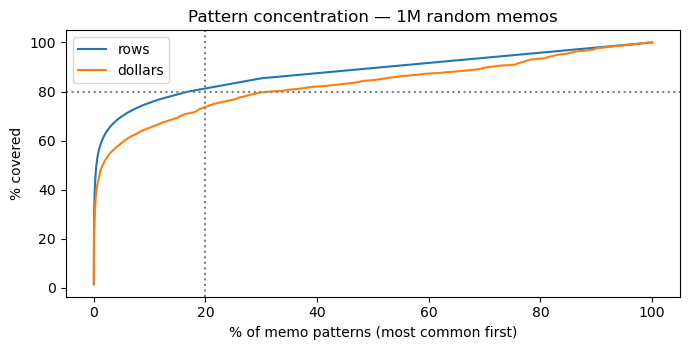

most common patterns:


,rows,dollars
pattern,,
transfer chime savings,17443,1735658.26
round up savings,11221,4971.06
walmart,8187,460154.32
transfer credit builder,7684,745513.68
online banking transfer,6626,1691967.54
apple com bill,6417,89224.35
mypay advance,6340,459656.00
mcdonald's,5792,71449.23
zelle,5327,1105307.32


In [14]:
def windows(dates, vs, ts):
    return pd.Series(np.select([dates.isna(), dates >= ts, dates >= vs], ["no_date", "test", "val"], "train"),
                     index=dates.index)

def cutoffs_70_85(dates):
    m = dates.dt.to_period("M").value_counts().sort_index()
    m = m.reindex(pd.period_range(m.index.min(), m.index.max(), freq="M"), fill_value=0)
    cum = m.cumsum() / m.sum()
    vs, ts = ((cum - .70).abs().idxmin() + 1).to_timestamp(), ((cum - .85).abs().idxmin() + 1).to_timestamp()
    if vs >= ts:
        q = dates.dropna().sort_values()
        vs, ts = q.iloc[int(len(q) * .70)].normalize(), q.iloc[int(len(q) * .85)].normalize()
    return vs, ts

def acct_hash(a): return hashlib.md5(f"{SEED}-{a}".encode()).hexdigest()

PLAN_PATH = OUT_DIR / "split_plan.json"
if PLAN_PATH.exists():
    plan = json.load(open(PLAN_PATH)); print("loaded frozen plan", PLAN_PATH)
else:
    vs, ts = pd.Timestamp(TEAM_VAL_START), pd.Timestamp(TEAM_TEST_START)
    per = windows(pool["date"], vs, ts)
    need = {"train": BUCKET_TARGETS["train"], "val": BUCKET_TARGETS["val"],
            "test": BUCKET_TARGETS["test_A"] + BUCKET_TARGETS["test_B"]}
    if all((per == w).sum() >= 2 * n for w, n in need.items()):
        source = "team cutoffs (full data)"
    else:
        print("team cutoffs leave", per.value_counts().to_dict(), "→ 70/85 rule on the pool's own dates")
        vs, ts = cutoffs_70_85(pool["date"]); source = "70/85 rule on the label accounts' dates"
    per = windows(pool["date"], vs, ts)
    old_per = windows(old["date"], vs, ts)
    old_early = set(old.loc[old_per.isin(["train", "val"]) & (old.account_key != ""), "account_key"])
    tcount = pool[per == "test"].groupby("account_key").size()
    cands = sorted([a for a, n in tcount.items() if n >= 3], key=lambda a: (a in old_early, acct_hash(a)))
    n_hold = max(3, round(HELDOUT_ACCOUNT_SHARE * len(tcount)))
    held, covered = [], 0
    for a in cands:
        if len(held) >= n_hold and covered >= 1.5 * BUCKET_TARGETS["test_B"]:
            break
        held.append(a); covered += tcount[a]
    plan = dict(val_start=str(vs.date()), test_start=str(ts.date()), cutoff_source=source,
                held_out_accounts=held, frozen_at=time.strftime("%Y-%m-%d %H:%M"))
    json.dump(plan, open(PLAN_PATH, "w"), indent=2)

VAL_START, TEST_START = pd.Timestamp(plan["val_start"]), pd.Timestamp(plan["test_start"])
HELD_OUT = set(plan["held_out_accounts"])
pool["period"] = windows(pool["date"], VAL_START, TEST_START)
pool["held_out"] = pool["account_key"].isin(HELD_OUT)
print(f"cutoffs ({plan['cutoff_source']}): train < {VAL_START:%Y-%m-%d} ≤ val < {TEST_START:%Y-%m-%d} ≤ test")
print(f"held-out accounts (Testing B): {len(HELD_OUT)} of {pool.account_key.nunique()}")
display(pd.crosstab(pool["period"], pool["held_out"].map({True: "held-out accts", False: "development accts"}))
        .reindex(["train", "val", "test"]))

def pareto(df, name):
    g = df.assign(dollars=df["amount"].abs()).groupby("pattern").agg(rows=("pattern", "size"), dollars=("dollars", "sum"))
    g = g.sort_values("rows", ascending=False)
    row_cum, usd_cum = g["rows"].cumsum() / g["rows"].sum(), g["dollars"].cumsum() / g["dollars"].sum()
    out = {"dataset": name, "rows": int(g["rows"].sum()), "patterns": len(g),
           "patterns for 80% of rows": int((row_cum < .80).sum() + 1),
           "top 20% of patterns → % rows": round(100 * row_cum.iloc[max(0, int(len(g) * .2) - 1)], 1)}
    for k in [10, 100, 1000]:
        if k <= len(g):
            out[f"top {k} → % rows"] = round(100 * row_cum.iloc[k - 1], 1)
            out[f"top {k} → % dollars"] = round(100 * usd_cum.iloc[k - 1], 1)
    return out, g, row_cum, usd_cum

pareto_rows, curves = [], {}
for name, df in [("label accounts", pool), ("1M random memos", general)]:
    o, g, rc, uc = pareto(df, name); pareto_rows.append(o); curves[name] = (g, rc, uc)
pareto_table = pd.DataFrame(pareto_rows).set_index("dataset").T
display(pareto_table)
g, rc, uc = curves["1M random memos"]
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(1, len(rc) + 1) / len(rc) * 100
ax.plot(x, rc.values * 100, label="rows"); ax.plot(x, uc.values * 100, label="dollars")
ax.axvline(20, ls=":", c="grey"); ax.axhline(80, ls=":", c="grey")
ax.set_xlabel("% of memo patterns (most common first)"); ax.set_ylabel("% covered"); ax.legend()
ax.set_title("Pattern concentration — 1M random memos"); plt.tight_layout()
plt.savefig(OUT_DIR / "pareto.png", dpi=150); plt.show()
print("most common patterns:"); display(g.head(15))

### 1.7. Choose the 900 memos

- **Evaluation buckets** (validation, Testing A, Testing B) are a plain random sample of their window, with a cap per
  account so one busy account can't dominate. They stay representative, so validation scores mean something.
- **Training bucket** is targeted, as the lecture asks:
  1. **sparse categories first** — categories with fewer than `SPARSE_TARGET` labels get rows the rules propose for
     them (distinct patterns first);
  2. **Pareto head** — up to 2 rows from each of the most common patterns ("include more sample of expected memos");
  3. **random remainder** — keeps memos no rule recognizes, so the model doesn't only see easy cases.
- If the label accounts run short in any bucket, the 1M random sample tops it up (rows tagged `general_sample`).

In [15]:
def pick(df, n, cap, taken, acct_counts):
    """Random rows not yet taken, at most `cap` per account (cap relaxes if needed)."""
    df = df[~df.index.isin(taken)]
    df = df.iloc[rng.permutation(len(df))]
    out = []
    while len(out) < n and len(df):
        for i, a in zip(df.index, df["account_key"]):
            if len(out) >= n:
                break
            if i not in taken and acct_counts[a] < cap:
                out.append(i); taken.add(i); acct_counts[a] += 1
        df = df[~df.index.isin(taken)]; cap *= 2
        if cap > 10 ** 6:
            break
    return out

taken, chosen = set(), {}
dev, hold = pool[~pool.held_out], pool[pool.held_out]
cap_eval = lambda n, d: max(2, math.ceil(1.5 * n / max(1, d["account_key"].nunique())))
for b, df in [("test_B", hold[hold.period == "test"]), ("test_A", dev[dev.period == "test"]), ("val", dev[dev.period == "val"])]:
    chosen[b] = pick(df, BUCKET_TARGETS[b], cap_eval(BUCKET_TARGETS[b], df), taken, Counter())

tr = dev[dev.period == "train"].copy()
T = BUCKET_TARGETS["train"]; cap_tr = max(10, math.ceil(0.08 * T)); train_ids = []; acct_counts = Counter()
tr[["rule_cat", "rule_conf", "rule_id", "rule_cue"]] = tr.apply(
    lambda x: pretag_full(x["memo_raw"], x["direction"]), axis=1, result_type="expand")
have = old["category"].value_counts()
sparse = sorted([c for c in CATEGORIES if c not in ("Uncertain", "Miscellaneous") and have.get(c, 0) < SPARSE_TARGET],
                key=lambda c: have.get(c, 0))
budget = int(0.35 * T); boost_log = {}
for c in sparse:
    want = min(SPARSE_TARGET - have.get(c, 0), budget - len(train_ids))
    cand = tr[(tr.rule_cat == c) & ~tr.index.isin(taken)]
    if want <= 0 or cand.empty:
        continue
    cand = cand.iloc[rng.permutation(len(cand))]
    cand = cand.assign(_r=cand.groupby("pattern").cumcount()).sort_values("_r", kind="stable")   # distinct patterns first
    got = pick(cand.head(want * 3), want, cap_tr, taken, acct_counts)
    train_ids += got; boost_log[c] = len(got)
head_budget = int(0.35 * T); head_ids = []
for p in tr["pattern"].value_counts().index:
    if len(head_ids) >= head_budget:
        break
    head_ids += pick(tr[tr.pattern == p], 2, cap_tr, taken, acct_counts)
train_ids += head_ids
train_ids += pick(tr, T - len(train_ids), cap_tr, taken, acct_counts)
chosen["train"] = train_ids

short = {b: BUCKET_TARGETS[b] - len(ids) for b, ids in chosen.items() if len(ids) < BUCKET_TARGETS[b]}
extra = []
if short:
    print("short buckets → topping up from the random sample:", short)
    gen = general[~general.account_key.isin(set(pool.account_key)) & (general.memo_raw.str.strip() != "")].copy()
    gen = gen[~txn_key(gen).isin(labeled_keys)]
    gen["period"] = windows(gen["date"], VAL_START, TEST_START)
    gen["held_out"] = gen["account_key"].map(lambda a: int(acct_hash(a), 16) % 5 == 0)
    win = {"train": "train", "val": "val", "test_A": "test", "test_B": "test"}
    gtaken, gcounts = set(), Counter()
    for b, n in short.items():
        df = gen[(gen.period == win[b]) & (gen.held_out == (b == "test_B"))]
        ids = pick(df, n, 3, gtaken, gcounts)
        extra.append(add_text_cols(gen.loc[ids].copy()).assign(bucket=b, source="general_sample"))
    HELD_OUT |= set(pd.concat(extra).query("bucket == 'test_B'")["account_key"]) if extra else set()

batch = pd.concat([pool.loc[ids].assign(bucket=b) for b, ids in chosen.items()] + extra, ignore_index=False)
batch = batch.drop(columns=[c for c in ["rule_cat", "rule_conf", "rule_id", "rule_cue"] if c in batch]).reset_index(drop=True)
print(f"selected {len(batch)} new memos | sparse-category boost: {boost_log} | Pareto head: {len(head_ids)}")
display(pd.crosstab(batch["bucket"], batch["source"], margins=True))
print("accounts in the batch:", batch.account_key.nunique(), "| held-out accounts in train/val:",
      int((batch.bucket.isin(["train", "val"]) & batch.account_key.isin(HELD_OUT)).sum()))

selected 900 new memos | sparse-category boost: {'Professional Services': 14, 'Health & Wellness': 25, 'Gifts & Donations': 25, 'Education': 25, 'Automotive': 24, 'Travel': 24, 'Bills & Utilities': 24, 'Fees & Adjustments': 23, 'Debt / Credit Payments': 20} | Pareto head: 204


source,same_accounts,All
bucket,,
test_A,90,90
test_B,90,90
train,585,585
val,135,135
All,900,900


accounts in the batch: 58 | held-out accounts in train/val: 0


### 1.8. Local AI suggestions → review file

**AI suggests, people adjudicate** (lecture: *allowed fields → local AI → propose → verify → label/review*). Two local
suggesters, nothing leaves DataHub:

1. **Pre-tag rules** — proposed label + the *quoted cue* that matched (e.g. `'Zelle'`) + confidence.
2. **PA4 FastText model** (100 labels) — a second opinion with a score; weak (14 % validation), so it only fills in
   when no rule matches and its score ≥ 0.5.

**Audit policy for speed** (lecture: *"AI labels accepted through audits"*). In the *training* bucket, rows with a
high-confidence rule suggestion are split: a random 25 % (≥ 30) are reviewed by you; if ≤ 5 % of those needed
correcting, the rest are accepted as `ai_accepted_via_audit` (logged separately). Any rule you corrected even once
loses that shortcut. **Validation and test rows are always reviewed individually** — they are the gold set.

`review_batch.csv` is never overwritten once it exists (your progress lives there).

In [16]:
OVERWRITE_REVIEW = False      

if REVIEW_PATH.exists() and not OVERWRITE_REVIEW:
    rv = pd.read_csv(REVIEW_PATH, dtype=str).fillna("")
    print(f"review file exists — keeping your progress: {(rv.review_status != '').sum()}/{len(rv)} reviewed")
else:
    b = batch.copy()
    r = b.apply(lambda x: pretag_full(x["memo_raw"], x["direction"]), axis=1, result_type="expand")
    b[["rule_cat", "rule_conf", "rule_id", "rule_cue"]] = r
    b["ft_label"], b["ft_prob"] = "", np.nan
    if PA4_MODEL.exists():
        pa4 = fasttext.load_model(str(PA4_MODEL))
        res = [pa4.f.predict((t or "empty_memo") + "\n", 1, 0.0, "strict") for t in b["text_lower"]]
        inv = {"__label__" + re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_"): c for c in CATEGORIES}
        b["ft_label"] = [inv.get(x[0][1], "") if x else "" for x in res]
        b["ft_prob"] = [float(x[0][0]) if x else np.nan for x in res]
        del pa4; gc.collect()
    use_rule = b["rule_cat"].notna()
    use_ft = ~use_rule & (b["ft_prob"] >= 0.5)
    b["ai_label"] = np.where(use_rule, b["rule_cat"], np.where(use_ft, b["ft_label"], ""))
    b["ai_conf"] = np.where(use_rule, b["rule_conf"], np.where(use_ft, "low", ""))
    b["ai_source"] = np.where(use_rule, "rule:" + b["rule_id"].astype(str), np.where(use_ft, "pa4_fasttext", ""))
    b["ai_cue"] = np.where(use_rule, b["rule_cue"].astype(str),
                           np.where(use_ft, "fasttext score " + b["ft_prob"].round(2).astype(str), ""))

    hi = b.index[(b.bucket == "train") & (b.ai_conf == "high")]
    n_audit = min(len(hi), max(AUDIT_MIN, math.ceil(AUDIT_FRACTION * len(hi))))
    audit_ids = set(rng.choice(hi, size=n_audit, replace=False)) if len(hi) else set()
    b["review_required"] = ~b.index.isin(hi) | b.index.isin(audit_ids)
    b["audit_sample"] = b.index.isin(audit_ids)

    b["pattern_n"] = b.groupby("pattern")["pattern"].transform("size")
    b = b.sort_values(["pattern_n", "pattern", "date"], ascending=[False, True, True]).reset_index(drop=True)
    b.insert(0, "review_id", np.arange(1, len(b) + 1))
    for c in ["final_label", "review_status", "note", "review_seconds", "reviewed_at"]:
        b[c] = ""
    keep = ["review_id", "bucket", "source", "account_key", "date", "amount", "direction", "memo_raw", "text_norm",
            "pattern", "pattern_n", "ai_label", "ai_conf", "ai_cue", "ai_source", "ft_label", "ft_prob",
            "review_required", "audit_sample", "final_label", "review_status", "note", "review_seconds", "reviewed_at"]
    b[keep].to_csv(REVIEW_PATH, index=False)
    rv = pd.read_csv(REVIEW_PATH, dtype=str).fillna("")
    print("wrote", REVIEW_PATH)

print(f"AI suggestion coverage: {(rv.ai_label != '').mean():.0%} "
      f"(high {(rv.ai_conf == 'high').mean():.0%}, low {(rv.ai_conf == 'low').mean():.0%}, none {(rv.ai_label == '').mean():.0%})")
print(f"to review individually: {(rv.review_required == 'True').sum()} | "
      f"of which audit sample: {(rv.audit_sample == 'True').sum()} | "
      f"deferred to the audit decision: {(rv.review_required != 'True').sum()}")
display(rv["ai_label"].replace("", "(no suggestion)").value_counts().to_frame("AI suggestions"))

review file exists — keeping your progress: 0/900 reviewed
AI suggestion coverage: 72% (high 54%, low 18%, none 28%)
to review individually: 651 | of which audit sample: 83 | deferred to the audit decision: 249


,AI suggestions
ai_label,
(no suggestion),256
Transfers,149
Debt / Credit Payments,65
Income / Deposits,61
Food & Drink,40
Travel,37
Fees & Adjustments,36
Bills & Utilities,28
Shopping,28


### 1.9. ⏸ Human review — `review_loop()`

> Instructions:
> 
>
> | input | meaning |
> |---|---|
> | **Enter** | accept the AI label (only when there is one) |
> | **a** *note* | accept, with a note |
> | **7** or **7** *note* | correct to category 7 (numbers from the table; typing a name also works) |
> | **u** *what evidence is missing* | unresolved — stays in Review, excluded from training |
> | **b** | back: undo the previous answer |
> | **s** / **q** | skip / save and quit (rerun the cell to continue where you stopped) |
>
> Every answer is saved immediately with the seconds it took — those timings answer Participation Question 1.
> Apply the group's category guide; when the memo can't support a category, use **20 Uncertain** (a decision) or
> **u** (you need more evidence — write what). Write a short note whenever you correct a suggestion — Participation
> Question 2 asks *which assumption failed*.
>
> When it says "nothing left to review", run **2.0**: it scores the audit sample. If the audit fails it marks more
> rows for review, then just run `review_loop()` again.



In [3]:
def review_loop(path=REVIEW_PATH, include_deferred=False):
    df = pd.read_csv(path, dtype=str).fillna("")
    todo = [i for i in df.index if df.at[i, "review_status"] == ""
            and (include_deferred or df.at[i, "review_required"] == "True")]
    hist, k, session = [], 0, {}
    code_table()                      
    while k < len(todo):
        i = todo[k]; r = df.loc[i]
        print("\n" + "─" * 90)          
        done = int(((df.review_status != "") & (df.review_required == "True")).sum())
        need = int((df.review_required == "True").sum())
        print(f"[{done}/{need} reviewed]   pattern: {r.pattern!r} ({r.pattern_n} in batch)\n")
        print(f"  MEMO   {r.memo_raw}")
        print(f"         ${float(r.amount or 0):,.2f}  {r.direction}  {r.date[:10]}\n")
        if r.ai_label:
            print(f"  AI     {r.ai_label}  [{r.ai_conf}]   cue: {r.ai_cue!r}   ({r.ai_source})")
        else:
            print("  AI     (no suggestion — pick a category)")
        if r.ft_label and r.ai_source != "pa4_fasttext":
            print(f"  PA4 FastText guess: {r.ft_label} ({float(r.ft_prob):.2f})")
        if r.pattern in session:
            print(f"  earlier this session, pattern {r.pattern!r} → {session[r.pattern]}")
        t0 = time.time()
        ans = input("Enter=accept | a/number/u [+note] | b back | s skip | ? codes | q quit > ").strip()
        secs = round(time.time() - t0, 1)
        cmd, _, note = ans.partition(" ")
        low = cmd.lower()
        if low == "q":
            break
        if low == "?":
            code_table(); continue
        if low == "s":
            k += 1; continue
        if low == "b":
            if hist:
                j = hist.pop()
                for c in ["final_label", "review_status", "note", "review_seconds", "reviewed_at"]:
                    df.at[j, c] = ""
                df.to_csv(path, index=False); k = todo.index(j)
            continue
        if low in ("", "a"):
            if not r.ai_label:
                continue
            lab, status = r.ai_label, "accepted"
        elif low == "u":
            lab, status = "", "unresolved"
        else:
            lab = parse_category(ans) or parse_category(cmd)
            if lab is None:
                continue
            if parse_category(ans):
                note = ""
            status = "accepted" if lab == r.ai_label else "corrected"
        df.loc[i, ["final_label", "review_status", "note", "review_seconds", "reviewed_at"]] = \
            [lab, status, note, str(secs), time.strftime("%Y-%m-%d %H:%M:%S")]
        df.to_csv(path, index=False)
        if lab:
            session[r.pattern] = lab
        hist.append(i); k += 1
    left = int(((df.review_status == "") & (df.review_required == "True")).sum())
    print(f"saved. reviewed: {(df.review_status != '').sum()} | still required: {left}")
    if left == 0:
        print("nothing left to review → run B0")
    return df

In [4]:
##  run to review (stop any time with q, rerun to continue)
_ = review_loop()

   1 Transfers                        11 Professional Services
   2 Food & Drink                     12 Debt / Credit Payments
   3 Shopping                         13 Finance & Investments
   4 Groceries                        14 Automotive
   5 Subscriptions & Entertainment    15 Travel
   6 Miscellaneous                    16 Bills & Utilities
   7 Gas                              17 Health & Wellness
   8 Income / Deposits                18 Gifts & Donations
   9 Cash Out (ATM)                   19 Education
  10 Fees & Adjustments               20 Uncertain

──────────────────────────────────────────────────────────────────────────────────────────
[874/900 reviewed]   pattern: 'scouting donation tx' (1 in batch)

  MEMO   RECURRING PAYMENT AUTHORIZED ON 11/28 SCOUTING* DONATION WWW.SCOUTING. TX S304333444647043 CARD 4672
         $51.50  debit  2024-11-29

  AI     Gifts & Donations  [high]   cue: 'DONATION'   (rule:donations)
  PA4 FastText guess: Shopping (0.08)


Enter=accept | a/number/u [+note] | b back | s skip | ? codes | q quit >  18 donation scouting



──────────────────────────────────────────────────────────────────────────────────────────
[875/900 reviewed]   pattern: 'service charge' (1 in batch)

  MEMO   Service Charge
         $12.50  debit  2024-12-09

  AI     Fees & Adjustments  [high]   cue: 'Service Charge'   (rule:fee)
  PA4 FastText guess: Shopping (0.08)


Enter=accept | a/number/u [+note] | b back | s skip | ? codes | q quit >  10 fee service charge



──────────────────────────────────────────────────────────────────────────────────────────
[876/900 reviewed]   pattern: 'service charge monthly' (1 in batch)

  MEMO   Service Charge          MONTHLY FEES
         $16.95  debit  2025-01-20

  AI     Fees & Adjustments  [high]   cue: 'Service Charge'   (rule:fee)
  PA4 FastText guess: Shopping (0.08)


Enter=accept | a/number/u [+note] | b back | s skip | ? codes | q quit >  10 fee service charge


... (43 outputs left out)

Enter=accept | a/number/u [+note] | b back | s skip | ? codes | q quit >  1 transfer



──────────────────────────────────────────────────────────────────────────────────────────
[899/900 reviewed]   pattern: 'zelle pmt theresa' (1 in batch)

  MEMO   ZELLE PMT THERESA 1TN000XMQSZV
         $10.00  debit  2023-12-13

  AI     Transfers  [high]   cue: 'ZELLE'   (rule:p2p)
  PA4 FastText guess: Income / Deposits (0.08)


Enter=accept | a/number/u [+note] | b back | s skip | ? codes | q quit >  1 transfer


saved. reviewed: 900 | still required: 0
nothing left to review → run B0


## Part B — retrain model and explain  change
Run after the review loop says nothing left to review. (If you restarted the kernel, run **1.1–1.3** and **1.6**
first; the scans are cached, so this takes seconds.)

### 2.0. Audit decision-making for the deferred AI labels

In [17]:
rv = pd.read_csv(REVIEW_PATH, dtype=str).fillna("")
for i in rv.index[(rv.final_label != "") & ~rv.final_label.isin(CATEGORIES)]:        # CSV edits: numbers / names
    rv.at[i, "final_label"] = parse_category(rv.at[i, "final_label"]) or rv.at[i, "final_label"]
rv["review_status"] = rv["review_status"].str.lower().str.strip().replace({"a": "accepted", "c": "corrected", "u": "unresolved"})
acc_mask = (rv.review_status == "accepted") & (rv.final_label == "")
rv.loc[acc_mask, "final_label"] = rv.loc[acc_mask, "ai_label"]
bad = rv[(rv.final_label != "") & ~rv.final_label.isin(CATEGORIES)]
assert bad.empty, f"unknown categories in review file: {bad.final_label.unique()}"

aud = rv[(rv.audit_sample == "True") & rv.review_status.isin(["accepted", "corrected"])]
aud_err = (aud.final_label != aud.ai_label).mean() if len(aud) else np.nan
bad_rules = set(aud.loc[aud.final_label != aud.ai_label, "ai_source"])
deferred = rv.index[(rv.review_required != "True") & (rv.review_status == "")]
print(f"audit sample reviewed: {len(aud)} | corrected: {(aud.final_label != aud.ai_label).sum()} "
      f"({aud_err:.1%}) | rules corrected at least once: {sorted(bad_rules) or 'none'}")
if ((rv.audit_sample == "True") & (rv.review_status == "")).any():
    print("finish reviewing the audit sample first (review_loop())")
elif aud_err <= AUDIT_MAX_ERROR:
    ok = [i for i in deferred if rv.at[i, "ai_source"] not in bad_rules]
    redo = [i for i in deferred if rv.at[i, "ai_source"] in bad_rules]
    rv.loc[ok, ["final_label", "review_status"]] = rv.loc[ok, ["ai_label"]].assign(s="ai_accepted_via_audit").values
    rv.loc[redo, "review_required"] = "True"
    print(f"audit passed → {len(ok)} accepted via audit; {len(redo)} from corrected rules sent to you for review")
else:
    rv.loc[deferred, "review_required"] = "True"
    print(f"audit failed ({aud_err:.1%} > {AUDIT_MAX_ERROR:.0%}) → all {len(deferred)} deferred rows need individual review")
rv.to_csv(REVIEW_PATH, index=False)
left = ((rv.review_required == "True") & (rv.review_status == "")).sum()
print("rows still waiting for review:", left, "→ run review_loop() again" if left else "→ continue to B1")

audit sample reviewed: 0 | corrected: 0 (nan%) | rules corrected at least once: none
finish reviewing the audit sample first (review_loop())
rows still waiting for review: 651 → run review_loop() again


### 2.1. Build `labels_v2.csv` (PA4 labels + reviewed batch) and re-split the PA4 labels

Lecture rule: *train on reviewed, nonempty labels*. Unresolved rows are excluded (kept in the review file with your
note). Every label carries a `label_source` so individually reviewed and audit-accepted labels can be reported
separately. 

In [15]:
rv = pd.read_csv(REVIEW_PATH, dtype=str).fillna("")
assert not ((rv.review_required == "True") & (rv.review_status == "")).any(), "review not finished — run review_loop()/B0"
new = rv[rv.final_label.isin(CATEGORIES)].copy()
new["label_source"] = np.select(
    [new.review_status == "ai_accepted_via_audit", new.ai_label == "", new.review_status == "corrected"],
    ["ai_accepted_via_audit", "human_no_suggestion", "human_corrected_ai"], "human_accepted_ai")
new = new.rename(columns={"final_label": "category", "bucket": "split"})
new["item_id"] = "n" + new["review_id"]
new["date"] = pd.to_datetime(new["date"], errors="coerce"); new["amount"] = pd.to_numeric(new["amount"])

o = old.copy()
per = windows(o["date"], VAL_START, TEST_START)
held = o["account_key"].isin(HELD_OUT)
undated_linked = set()
cache = PA4_DIR / "scan_cache_v3"
if cache.exists():
    f = pd.concat([pd.read_pickle(p) for p in cache.glob("*.pkl")], ignore_index=True)
    f["account_key"] = f["account_key"].astype(str).str.replace(r"\.0$", "", regex=True)
    hit = set(f.loc[f.account_key.isin(HELD_OUT), "memo_raw"])
    undated_linked = set(o.loc[(per == "no_date") & o.memo_raw.isin(hit), "item_id"])
o["split"] = np.select(
    [(per == "no_date") & o.item_id.isin(undated_linked), per == "no_date", held & (per == "test"), held,
     per == "test", per == "val"],
    ["excluded", "train", "test_B", "excluded", "test_A", "val"], "train")
o["label_source"] = np.where(o.category != o.category_pa4, "pa4_human_fixed", "pa4_human")
o["review_status"] = "pa4"

cols = ["item_id", "split", "label_source", "review_status", "account_key", "date", "amount", "direction",
        "memo_raw", "category", "note"]
labels = pd.concat([o[cols], new[cols]], ignore_index=True)
labels = add_text_cols(labels)
labels.to_csv(OUT_DIR / "labels_v2.csv", index=False)

print(f"labels_v2: {len(labels)} rows ({len(o)} PA4 + {len(new)} new) | unresolved left out: "
      f"{(rv.review_status == 'unresolved').sum()} | PA4 labels excluded (held-out account outside test window): "
      f"{(o.split == 'excluded').sum()}")
display(pd.crosstab(labels["label_source"], labels["split"], margins=True))

labels_v2: 1000 rows (100 PA4 + 900 new) | unresolved left out: 0 | PA4 labels excluded (held-out account outside test window): 6


split,excluded,test_A,test_B,train,val,All
label_source,,,,,,
human_accepted_ai,0,50,46,386,88,570
human_corrected_ai,0,3,4,58,9,74
human_no_suggestion,0,37,40,141,38,256
pa4_human,6,0,0,92,0,98
pa4_human_fixed,0,0,0,2,0,2
All,6,90,90,679,135,1000


### 2.2. Category guide check: class counts, splits, leakage

From the Lecture: cover all categories; this flags classes with less than 5 training rows.

In [16]:
use = labels[labels.split != "excluded"]

counts = pd.crosstab(use["category"], use["split"]).reindex(index=CATEGORIES, fill_value=0)

counts = counts.reindex(columns=["train", "val", "test_A", "test_B"], fill_value=0)
counts["total"] = counts.sum(axis=1)
counts["PA4 total"] = old.groupby("category").size().reindex(CATEGORIES, fill_value=0)
counts["flag"] = np.select([counts.total == 0, counts.train == 0, counts.train < 5], ["missing", "no train rows", "<5 train"], "")
display(counts)
print("categories with no labels at all:", list(counts.index[counts.total == 0]) or "none")
print("categories with <5 training rows:", list(counts.index[(counts.train < 5) & (counts.total > 0)]) or "none")

trv = use[use.split.isin(["train", "val"])]
assert not (set(trv.account_key) & HELD_OUT), "a held-out account appears in train/val"
assert (use.loc[(use.split == "train") & use.date.notna(), "date"] < VAL_START).all(), "a training row is not before the cutoff"
kd = use[use.date.notna() & (use.account_key != "")]
assert not txn_key(kd).duplicated().any(), "the same transaction appears twice"
train_text = set(use.loc[use.split == "train", "text_norm"])
for s in ["val", "test_A", "test_B"]:
    d = use[use.split == s]
    print(f"{s:7s}: {len(d):4d} labels | {d.account_key.nunique():3d} accounts | accounts also in train: "
          f"{len(set(d.account_key) & set(use.loc[use.split == 'train', 'account_key']) - {''}):3d} | "
          f"identical memo text in train: {d.text_norm.isin(train_text).sum()}")
print("leakage checks passed")
counts.to_csv(OUT_DIR / "class_counts.csv")

split,train,val,test_A,test_B,total,PA4 total,flag
category,,,,,,,
Transfers,121,35,17,20,193,25,
Food & Drink,94,21,10,9,134,19,
Shopping,44,6,5,0,55,12,
Groceries,24,2,4,1,31,4,
Subscriptions & Entertainment,51,11,9,27,98,12,
Miscellaneous,2,1,3,0,6,0,<5 train
Gas,30,4,4,1,39,8,
Income / Deposits,44,11,11,11,77,6,
Cash Out (ATM),10,1,3,1,15,3,


categories with no labels at all: none
categories with <5 training rows: ['Miscellaneous']
val    :  135 labels |  24 accounts | accounts also in train:  24 | identical memo text in train: 38
test_A :   90 labels |  22 accounts | accounts also in train:  22 | identical memo text in train: 20
test_B :   90 labels |   5 accounts | accounts also in train:   0 | identical memo text in train: 11
leakage checks passed


### 2.3. Reading early FastText results — what changed with 10× the labels?

Same validation rows for every comparison (lecture: *fix the labels, cleaning and split*):

- majority-class baseline: the bar to beat (Group 2: 26.7 %);
- PA4 model (100 labels, unchanged) scored on the new validation set;
- PA4 settings retrained on the new labels: isolates the effect of more labels;
- cleaning: PA4 lowercase vs. `text_norm` with masked IDs, compared at a well-trained setting (50 epochs,
  lr 0.5); the better one (ties → `text_norm`) is kept for every later step.



In [17]:
SETS = {s: use[use.split == s].reset_index(drop=True) for s in ["train", "val", "test_A", "test_B"]}
def to_label(c): return "__label__" + re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_")
INV = {to_label(c): c for c in CATEGORIES}

def write_ft(df, path, col):
    with open(path, "w") as f:
        for c, t in zip(df["category"], df[col]):
            f.write(f"{to_label(c)} {t or 'empty_memo'}\n")

BASE = dict(epoch=25, lr=0.1, dim=100, minCount=1, wordNgrams=2, minn=3, maxn=6, bucket=BUCKET,
            thread=FT_THREAD, verbose=0, seed=SEED)

def fit(col, train=None, **params):
    p = {**BASE, **params}
    path = OUT_DIR / f"_train_{col}.txt"
    write_ft(SETS["train"] if train is None else train, path, col)
    t0 = time.time()
    try:
        m = fasttext.train_supervised(input=str(path), **p)
    except RuntimeError as e:             # some fasttext builds hit "Encountered NaN" on a few settings
        return None, time.time() - t0, str(e)
    return m, time.time() - t0, ""

def predict(model, texts):
    out = [model.f.predict((t or "empty_memo") + "\n", 1, 0.0, "strict") for t in texts]
    return [INV.get(x[0][1], "?") if x else "?" for x in out], np.array([x[0][0] if x else 0.0 for x in out])

def scores(y, p):
    y, p = list(y), list(p)
    return dict(n=len(y), accuracy=float(np.mean(np.array(y) == np.array(p))) if y else np.nan,
                macro_f1=float(f1_score(y, p, labels=sorted(set(y)), average="macro", zero_division=0)) if y else np.nan)

def model_mb(m):
    a = m.f.getArgs(); rows = len(m.words) + (a.bucket if (a.wordNgrams > 1 or a.maxn > 0) else 0)
    return round((rows + len(m.labels)) * a.dim * 4 / 1e6, 1)

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = k / n; d = 1 + z * z / n; c = ph + z * z / (2 * n); h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

V = SETS["val"]; rows = []
maj = SETS["train"]["category"].value_counts().idxmax()
rows.append(dict(model=f"majority class ({maj})", train_rows=len(SETS["train"]), **scores(V.category, [maj] * len(V))))
if PA4_MODEL.exists():
    pa4 = fasttext.load_model(str(PA4_MODEL))
    rows.append(dict(model="PA4 model (100 labels, 5 epochs)", train_rows=43, **scores(V.category, predict(pa4, V.text_lower)[0])))
    del pa4; gc.collect()
for col in ["text_lower", "text_norm"]:
    for name, prm in [("PA4 settings (5 epochs)", PA4_PARAMS), ("50 epochs lr 0.5", dict(epoch=50, lr=0.5))]:
        m, secs, err = fit(col, **prm)
        if m is None:
            rows.append(dict(model=f"new labels, {name}, {col}", error=err)); continue
        rows.append(dict(model=f"new labels, {name}, {col}", train_rows=len(SETS["train"]),
                         **scores(V.category, predict(m, V[col])[0]), fit_s=round(secs, 2)))
        del m; gc.collect()
change = pd.DataFrame(rows)
display(change.style.format({"accuracy": "{:.1%}", "macro_f1": "{:.3f}"}, na_rep=""))

TEXT_COL = "text_norm" if (change[change.model.str.contains("lr 0.5, text_norm")].macro_f1.max()
                          >= change[change.model.str.contains("lr 0.5, text_lower")].macro_f1.max() - 0.005) else "text_lower"
print(f"cleaning kept for all experiments: {TEXT_COL}")
k = int(round(change[change.model.str.contains(f"lr 0.5, {TEXT_COL}")].accuracy.iloc[0] * len(V)))
lo, hi = wilson(k, len(V))
print(f"one validation row = {100 / len(V):.1f} points (PA4: {100 / 7:.1f}; team PA4: 1.7) | "
      f"95% interval on that accuracy: {lo:.0%}–{hi:.0%}")
change.to_csv(OUT_DIR / "change_vs_pa4.csv", index=False)

,model,train_rows,n,accuracy,macro_f1,fit_s
0,majority class (Transfers),679,135,25.9%,0.023,
1,"PA4 model (100 labels, 5 epochs)",43,135,20.0%,0.075,
2,"new labels, PA4 settings (5 epochs), text_lower",679,135,38.5%,0.098,0.400000
3,"new labels, 50 epochs lr 0.5, text_lower",679,135,65.9%,0.502,1.550000
4,"new labels, PA4 settings (5 epochs), text_norm",679,135,30.4%,0.064,0.330000
5,"new labels, 50 epochs lr 0.5, text_norm",679,135,68.1%,0.492,1.140000


cleaning kept for all experiments: text_lower
one validation row = 0.7 points (PA4: 14.3; team PA4: 1.7) | 95% interval on that accuracy: 58%–73%


### 2.4. Experiment plan — one question per stage, validation only, test untouched

| Stage | Question | Grid |
|---|---|---|
| 1 | Do word pairs and character pieces help with truncated merchant names? | `wordNgrams` 1/2/3 × subwords off / (3,5) / (2,5); then `minCount` 1/2/5 |
| 2 | How much learning effort? | `epoch` 5/25/50/100 × `lr` 0.05/0.1/0.5 |
| 3 | Does a bigger vector help? (tried last) | `dim` 50/100/200 |
| ✓ | Is the winner stable? | top 3 settings × 3 seeds |

Each run records validation **macro-F1**, accuracy, fit time and model
size. Ties go to the faster or smaller model. A failed run (FastText's `NaN` bug) is recorded, not hidden.

,stage,setting,fit_s,error,n,accuracy,macro_f1,train_acc,model_mb
0,1,"wordNgrams=1, no subwords",0.030000,Encountered NaN.,,,,,
1,1,"wordNgrams=1, char 3-5",0.760000,,135.000000,25.9%,0.023,17.8%,800.700000
2,1,"wordNgrams=1, char 2-5",0.890000,,135.000000,25.9%,0.023,17.8%,800.700000
3,1,"wordNgrams=2, no subwords",0.350000,,135.000000,46.7%,0.185,40.8%,800.700000
4,1,"wordNgrams=2, char 3-5",0.790000,,135.000000,25.9%,0.023,17.8%,800.700000
5,1,"wordNgrams=2, char 2-5",0.940000,,135.000000,25.9%,0.023,17.8%,800.700000
6,1,"wordNgrams=3, no subwords",0.380000,,135.000000,43.7%,0.149,35.2%,800.700000
7,1,"wordNgrams=3, char 3-5",0.840000,,135.000000,25.9%,0.023,17.8%,800.700000
8,1,"wordNgrams=3, char 2-5",0.980000,,135.000000,25.9%,0.023,17.8%,800.700000
9,1,best features + minCount=2,0.350000,,135.000000,50.4%,0.265,45.8%,800.200000


,params,runs,mean_macro_f1,sd
0,"{""wordNgrams"": 2, ""minn"": 0, ""maxn"": 0, ""minCount"": 5, ""epoch"": 100, ""lr"": 0.5, ""dim"": 200}",3,0.473,0.000
1,"{""wordNgrams"": 2, ""minn"": 0, ""maxn"": 0, ""minCount"": 5, ""epoch"": 100, ""lr"": 0.5}",3,0.467,0.001
2,"{""wordNgrams"": 2, ""minn"": 0, ""maxn"": 0, ""minCount"": 5, ""epoch"": 100, ""lr"": 0.5, ""dim"": 100}",3,0.467,0.001


chosen (best mean macro-F1 over seeds): {'wordNgrams': 2, 'minn': 0, 'maxn': 0, 'minCount': 5, 'epoch': 100, 'lr': 0.5, 'dim': 200} | tuning time 23s


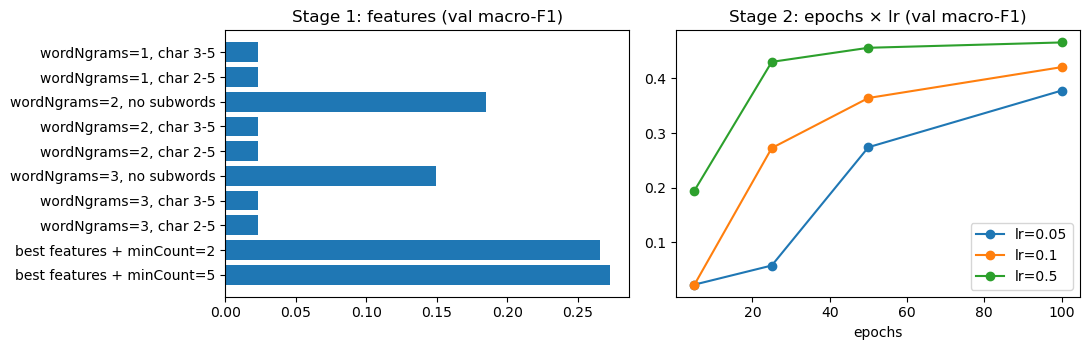

In [18]:
exp_rows = []
def run(stage, name, **params):
    m, secs, err = fit(TEXT_COL, **params)
    row = dict(stage=stage, setting=name, params=json.dumps(params), fit_s=round(secs, 2))
    if m is None:
        row["error"] = err[:60]
    else:
        p, _ = predict(m, SETS["val"][TEXT_COL])
        row.update(scores(SETS["val"].category, p), train_acc=scores(SETS["train"].category, predict(m, SETS["train"][TEXT_COL])[0])["accuracy"],
                   model_mb=model_mb(m))
        del m; gc.collect()
    exp_rows.append(row); return row

def best_of(stage):
    d = pd.DataFrame([r for r in exp_rows if r["stage"] == stage and "macro_f1" in r])
    return json.loads(d.sort_values(["macro_f1", "accuracy", "fit_s"], ascending=[False, False, True]).iloc[0]["params"])

t_tune = time.time()
# stage 1: features
for wn in [1, 2, 3]:
    for sub, (mn, mx) in [("no subwords", (0, 0)), ("char 3-5", (3, 5)), ("char 2-5", (2, 5))]:
        run(1, f"wordNgrams={wn}, {sub}", wordNgrams=wn, minn=mn, maxn=mx)
b1 = best_of(1)
for mc in [2, 5]:
    run(1, f"best features + minCount={mc}", **b1, minCount=mc)
b1 = best_of(1)
# stage 2: learning effort
for ep in [5, 25, 50, 100]:
    for lr in [0.05, 0.1, 0.5]:
        run(2, f"epoch={ep}, lr={lr}", **{**b1, "epoch": ep, "lr": lr})
b2 = best_of(2)
# stage 3: vector size
for dim in [50, 100, 200]:
    run(3, f"dim={dim}", **{**b2, "dim": dim})
b3 = best_of(3)

# stability: top 3 distinct settings × 3 seeds
d = pd.DataFrame([r for r in exp_rows if "macro_f1" in r]).drop_duplicates("params")
top = d.sort_values(["macro_f1", "fit_s"], ascending=[False, True]).head(3)["params"].tolist()
for pjs in top:
    for s in [1, 2]:
        run("seed", f"seed={s}", **{**json.loads(pjs), "seed": s})
TUNING_SECONDS = time.time() - t_tune

exp = pd.DataFrame(exp_rows)
stab = []
for pjs in top:
    p = json.loads(pjs)
    vals = [r["macro_f1"] for r in exp_rows if "macro_f1" in r and
            {k: v for k, v in json.loads(r["params"]).items() if k != "seed"} == {k: v for k, v in p.items() if k != "seed"}]
    stab.append(dict(params=pjs, runs=len(vals), mean_macro_f1=np.mean(vals), sd=np.std(vals)))
stab = pd.DataFrame(stab).sort_values("mean_macro_f1", ascending=False)
BEST = {k: v for k, v in json.loads(stab.iloc[0]["params"]).items() if k != "seed"}

display(exp.drop(columns=["params"]).style.format({"accuracy": "{:.1%}", "macro_f1": "{:.3f}", "train_acc": "{:.1%}"}, na_rep=""))
display(stab.style.format({"mean_macro_f1": "{:.3f}", "sd": "{:.3f}"}))
print(f"chosen (best mean macro-F1 over seeds): {BEST} | tuning time {TUNING_SECONDS:.0f}s")
exp.to_csv(OUT_DIR / "experiments.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
s1 = exp[(exp.stage == 1) & exp.get("macro_f1", pd.Series(dtype=float)).notna()]
axes[0].barh(s1.setting, s1.macro_f1); axes[0].set_title("Stage 1: features (val macro-F1)"); axes[0].invert_yaxis()
s2 = exp[exp.stage == 2].dropna(subset=["macro_f1"]).copy()
s2["ep"] = s2.params.map(lambda x: json.loads(x)["epoch"]); s2["lr"] = s2.params.map(lambda x: json.loads(x)["lr"])
for lr, g in s2.groupby("lr"):
    axes[1].plot(g.ep, g.macro_f1, marker="o", label=f"lr={lr}")
axes[1].set_xlabel("epochs"); axes[1].set_title("Stage 2: epochs × lr (val macro-F1)"); axes[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "experiments.png", dpi=150); plt.show()

### 2.5. Final model: class quality on validation (per-class P/R/F1, confusion matrix, reviewed errors)

final: {'wordNgrams': 2, 'minn': 0, 'maxn': 0, 'minCount': 5, 'epoch': 100, 'lr': 0.5, 'dim': 200} | fit 1.34s on 679 rows | file 1600 MB
validation: accuracy 62.2%, macro-F1 0.473 (n=135)


,precision,recall,f1-score,support,train_rows
Transfers,0.87,0.97,0.92,35,121
Food & Drink,0.80,0.57,0.67,21,94
Uncertain,0.50,0.33,0.40,12,18
Income / Deposits,0.88,0.64,0.74,11,44
Subscriptions & Entertainment,0.50,0.18,0.27,11,51
Debt / Credit Payments,0.54,0.78,0.64,9,45
Fees & Adjustments,1.00,0.62,0.77,8,41
Shopping,0.14,0.17,0.15,6,44
Travel,0.71,1.00,0.83,5,33
Gas,0.19,0.75,0.30,4,30


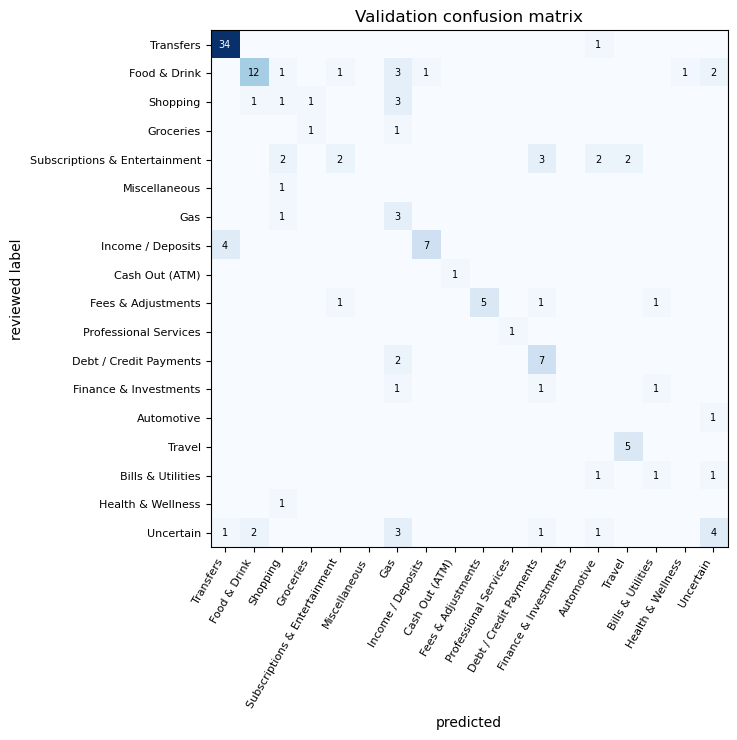

most-confused pairs (reviewed → predicted): [(('Income / Deposits', 'Transfers'), 4), (('Subscriptions & Entertainment', 'Debt / Credit Payments'), 3), (('Food & Drink', 'Gas'), 3), (('Uncertain', 'Gas'), 3), (('Shopping', 'Gas'), 3), (('Food & Drink', 'Uncertain'), 2)]
errors where no memo word appeared in training: 3 of 51


,item_id,memo_raw,category,predicted,score,label_source,unseen_words,account_key,amount
95,n666,Grant Cash Adv 04/17 #XXXXX1186 PMNT RCVD Grant Cash Advanc,Income / Deposits,Transfers,0.998480,human_no_suggestion,False,359024,100.00
121,n830,TYPE: INST XFER ID: PAYPALSI77 CO: PAYPAL NAME: [NAME] ACH ECC WEB,Uncertain,Transfers,0.997140,human_corrected_ai,False,170600,0.00
68,n448,Transfer MoneyLion Instacash,Income / Deposits,Transfers,0.996717,human_accepted_ai,False,359024,100.00
67,n447,Transfer MoneyLion Instacash,Income / Deposits,Transfers,0.996717,human_accepted_ai,False,1074135,100.00
117,n810,Target,Shopping,Gas,0.959585,human_accepted_ai,False,359024,38.61
109,n762,Ralphs,Groceries,Gas,0.959585,human_accepted_ai,True,170600,10.22
80,n553,CDSR,Uncertain,Gas,0.959585,human_no_suggestion,True,15451,200.00
99,n697,JCPenney,Shopping,Gas,0.959585,human_no_suggestion,True,922931,41.12
23,n104,Chick-fil-A,Food & Drink,Gas,0.959191,human_accepted_ai,False,858967,15.93
22,n103,Chick-fil-A,Food & Drink,Gas,0.959191,human_accepted_ai,False,898153,23.94


In [19]:
final, FIT_SECONDS, err = fit(TEXT_COL, **BEST)
assert final is not None, err
MODEL_PATH = OUT_DIR / "memo_fasttext_pa5.bin"
final.save_model(str(MODEL_PATH))
vp, vs_ = predict(final, SETS["val"][TEXT_COL])
val = SETS["val"].assign(predicted=vp, score=vs_)
val["correct"] = val.predicted == val.category
VAL_SCORES = scores(val.category, val.predicted)
print(f"final: {BEST} | fit {FIT_SECONDS:.2f}s on {len(SETS['train'])} rows | file {MODEL_PATH.stat().st_size / 1e6:.0f} MB")
print(f"validation: accuracy {VAL_SCORES['accuracy']:.1%}, macro-F1 {VAL_SCORES['macro_f1']:.3f} (n={len(val)})")

rep = pd.DataFrame(classification_report(val.category, val.predicted, labels=sorted(set(val.category)),
                                         output_dict=True, zero_division=0)).T
rep = rep.loc[[c for c in rep.index if c in CATEGORIES]].sort_values("support", ascending=False)
rep["train_rows"] = rep.index.map(SETS["train"].category.value_counts()).fillna(0).astype(int)
display(rep.style.format({"precision": "{:.2f}", "recall": "{:.2f}", "f1-score": "{:.2f}", "support": "{:.0f}"}))

labs = [c for c in CATEGORIES if c in set(val.category) | set(val.predicted)]
cm = confusion_matrix(val.category, val.predicted, labels=labs)
fig, ax = plt.subplots(figsize=(9, 7.5)); im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs, fontsize=8)
for i in range(len(labs)):
    for j in range(len(labs)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("reviewed label"); ax.set_title("Validation confusion matrix")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion.png", dpi=150); plt.show()

train_tok = Counter(t for x in SETS["train"][TEXT_COL] for t in set(x.split()) if not t.startswith("<"))
errors = val[~val.correct].copy()
errors["unseen_words"] = errors[TEXT_COL].map(lambda x: all(train_tok.get(t, 0) == 0 for t in x.split() if not t.startswith("<")))
errors = errors[["item_id", "memo_raw", "category", "predicted", "score", "label_source", "unseen_words", "account_key", "amount"]]
errors.to_parquet(OUT_DIR / "errors.parquet", index=False); errors.to_csv(OUT_DIR / "errors.csv", index=False)
print("most-confused pairs (reviewed → predicted):", Counter(zip(errors.category, errors.predicted)).most_common(6))
print(f"errors where no memo word appeared in training: {errors.unseen_words.sum()} of {len(errors)}")
display(errors.sort_values("score", ascending=False).head(20))

### 2.6. Review coverage: choose the review cutoff on validation

Lecture's worked threshold: accept a prediction when its score ≥ cutoff (and it isn't `Uncertain`); everything else
goes to human review. **Row coverage** = accepted / eligible, **dollar coverage** = accepted $ / eligible $,
**accepted error** = wrong among accepted. Rule: the highest-coverage cutoff whose accepted error ≤ 5 %.

In [20]:
def coverage(d, cut):
    acc = (d.score >= cut) & (d.predicted != "Uncertain")
    a = d[acc]
    return dict(cutoff=cut, accepted=int(acc.sum()), eligible=len(d), row_coverage=acc.mean(),
                dollar_coverage=a.amount.abs().sum() / d.amount.abs().sum() if d.amount.abs().sum() else np.nan,
                accepted_error=(~a.correct).mean() if len(a) else np.nan, to_review=int((~acc).sum()))

cov = pd.DataFrame([coverage(val, c) for c in [0, .3, .4, .5, .6, .7, .8, .9, .95]])
okc = cov[(cov.accepted_error <= MAX_ACCEPTED_ERROR) & (cov.accepted >= 10)]
if len(okc):
    CUTOFF = float(okc.sort_values(["row_coverage", "cutoff"], ascending=[False, True]).iloc[0].cutoff); why = f"≤{MAX_ACCEPTED_ERROR:.0%} accepted error, most coverage"
else:
    c2 = cov[cov.accepted >= 10].sort_values(["accepted_error", "row_coverage"], ascending=[True, False])
    CUTOFF = float(c2.iloc[0].cutoff) if len(c2) else 0.9; why = f"no cutoff reached ≤{MAX_ACCEPTED_ERROR:.0%}; lowest accepted error"
display(cov.style.format({"row_coverage": "{:.0%}", "dollar_coverage": "{:.0%}", "accepted_error": "{:.1%}"}, na_rep="—"))
print(f"chosen review cutoff: {CUTOFF} ({why})")
VAL_COV = coverage(val, CUTOFF)

,cutoff,accepted,eligible,row_coverage,dollar_coverage,accepted_error,to_review
0,0.000000,127,135,94%,95%,37.0%,8
1,0.300000,118,135,87%,93%,33.9%,17
2,0.400000,113,135,84%,91%,31.0%,22
3,0.500000,110,135,81%,90%,30.9%,25
4,0.600000,101,135,75%,88%,25.7%,34
5,0.700000,92,135,68%,73%,22.8%,43
6,0.800000,85,135,63%,65%,18.8%,50
7,0.900000,77,135,57%,63%,16.9%,58
8,0.950000,73,135,54%,62%,13.7%,62


chosen review cutoff: 0.95 (no cutoff reached ≤5%; lowest accepted error)


### 2.7. Test Group A vs. Test Group B 


In [21]:
TEST = {}
for s in ["test_A", "test_B"]:
    p, sc = predict(final, SETS[s][TEXT_COL])
    d = SETS[s].assign(predicted=p, score=sc); d["correct"] = d.predicted == d.category
    TEST[s] = d
shared = set(TEST["test_A"].category) & set(TEST["test_B"].category)
tt = pd.DataFrame([dict(set=s, **scores(d.category, d.predicted), accounts=d.account_key.nunique(),
                        acc_on_shared_classes=d[d.category.isin(shared)].correct.mean(),
                        **{k: v for k, v in coverage(d, CUTOFF).items() if k in ("row_coverage", "dollar_coverage", "accepted_error")})
                   for s, d in [("validation", val), ("test_A", TEST["test_A"]), ("test_B", TEST["test_B"])]])
display(tt.style.format({"accuracy": "{:.1%}", "macro_f1": "{:.3f}", "acc_on_shared_classes": "{:.1%}",
                         "row_coverage": "{:.0%}", "dollar_coverage": "{:.0%}", "accepted_error": "{:.1%}"}, na_rep="—"))
mix = pd.concat({s: TEST[s].category.value_counts(normalize=True) for s in TEST}, axis=1).fillna(0)
mix["train"] = SETS["train"].category.value_counts(normalize=True)
display((mix * 100).round(1).sort_values("test_A", ascending=False).rename(columns=lambda c: c + " %"))
for s in TEST:
    e = TEST[s][~TEST[s].correct]
    print(f"{s} most-confused:", Counter(zip(e.category, e.predicted)).most_common(5))
pd.concat([val.assign(set="val")] + [d.assign(set=s) for s, d in TEST.items()]).to_csv(OUT_DIR / "predictions.csv", index=False)

,set,n,accuracy,macro_f1,accounts,acc_on_shared_classes,row_coverage,dollar_coverage,accepted_error
0,validation,135,62.2%,0.473,24,68.6%,54%,62%,13.7%
1,test_A,90,43.3%,0.356,22,47.9%,41%,43%,13.5%
2,test_B,90,45.6%,0.466,5,45.6%,39%,31%,14.3%


,test_A %,test_B %,train %
category,,,
Transfers,18.9,22.2,17.8
Debt / Credit Payments,12.2,11.1,6.6
Income / Deposits,12.2,12.2,6.5
Food & Drink,11.1,10.0,13.8
Subscriptions & Entertainment,10.0,30.0,7.5
Uncertain,8.9,0.0,2.7
Shopping,5.6,0.0,6.5
Gas,4.4,1.1,4.4
Groceries,4.4,1.1,3.5


test_A most-confused: [(('Uncertain', 'Gas'), 5), (('Subscriptions & Entertainment', 'Automotive'), 4), (('Gas', 'Food & Drink'), 2), (('Debt / Credit Payments', 'Subscriptions & Entertainment'), 2), (('Subscriptions & Entertainment', 'Food & Drink'), 2)]
test_B most-confused: [(('Subscriptions & Entertainment', 'Debt / Credit Payments'), 8), (('Subscriptions & Entertainment', 'Automotive'), 8), (('Subscriptions & Entertainment', 'Gas'), 6), (('Finance & Investments', 'Debt / Credit Payments'), 4), (('Income / Deposits', 'Transfers'), 4)]


In [23]:
ALT = {**BEST, "epoch": 50}          
print("current final:", BEST)
print("alternative:  ", ALT)

alt, alt_secs, err = fit(TEXT_COL, **ALT)
assert alt is not None, err

rows = []
for name, m in [("100 epochs (current final)", final), ("50 epochs", alt)]:
    for s in ["train", "val", "test_A", "test_B"]:
        d = SETS[s]
        p, sc = predict(m, d[TEXT_COL])
        dd = d.assign(predicted=p, score=sc, correct=np.array(p) == d["category"].to_numpy())
        cov = coverage(dd, CUTOFF)
        rows.append(dict(model=name, set=s, **scores(d.category, p),
                         gas_predictions=int((np.array(p) == "Gas").sum()),
                         row_coverage=cov["row_coverage"], accepted_error=cov["accepted_error"]))
cmp = pd.DataFrame(rows)
display(cmp.style.format({"accuracy": "{:.1%}", "macro_f1": "{:.3f}", "row_coverage": "{:.0%}",
                          "accepted_error": "{:.1%}"}, na_rep="—"))

# quick side-by-side of accuracy
display(cmp.pivot(index="set", columns="model", values="accuracy")
           .reindex(["train", "val", "test_A", "test_B"])
           .style.format("{:.1%}"))
print(f"50-epoch fit time: {alt_secs:.2f}s | review cutoff used for coverage: {CUTOFF}")

current final: {'wordNgrams': 2, 'minn': 0, 'maxn': 0, 'minCount': 5, 'epoch': 100, 'lr': 0.5, 'dim': 200}
alternative:   {'wordNgrams': 2, 'minn': 0, 'maxn': 0, 'minCount': 5, 'epoch': 50, 'lr': 0.5, 'dim': 200}


,model,set,n,accuracy,macro_f1,gas_predictions,row_coverage,accepted_error
0,100 epochs (current final),train,679,99.9%,0.999,30,97%,0.0%
1,100 epochs (current final),val,135,62.2%,0.473,16,54%,13.7%
2,100 epochs (current final),test_A,90,43.3%,0.356,13,41%,13.5%
3,100 epochs (current final),test_B,90,45.6%,0.466,11,39%,14.3%
4,50 epochs,train,679,99.9%,0.999,30,94%,0.0%
5,50 epochs,val,135,60.7%,0.455,16,47%,6.2%
6,50 epochs,test_A,90,43.3%,0.360,13,38%,5.9%
7,50 epochs,test_B,90,45.6%,0.459,11,34%,6.5%


model,100 epochs (current final),50 epochs
set,,
train,99.9%,99.9%
val,62.2%,60.7%
test_A,43.3%,43.3%
test_B,45.6%,45.6%


50-epoch fit time: 0.86s | review cutoff used for coverage: 0.95


### 2.8. Measure quality and the effort to scale → Participation Question 1

*Record hardware, batch size, model settings and eligible rows with every timing.*

- **Training**: fit time on the labeled rows (setup/tuning time reported separately).
- **Inference**: model load time, then the final model labels the **1,000,000 random memos** from A5 in batches;
  cleaning time is measured separately. Extrapolated to the full ~201.7M rows.
- **Human review**: your seconds per memo from the review loop.

In [18]:
HUMAN_MINUTES_OVERRIDE = None     # only if you reviewed in the CSV instead of review_loop(): total minutes spent
BATCH = 10_000
FULL_ROWS = 201_711_849

def mem_gb():
    try:
        kb = int([l for l in open("/proc/meminfo") if l.startswith("MemTotal")][0].split()[1]); return round(kb / 1e6, 1)
    except Exception:
        return None
HW = dict(platform=platform.platform(), processor=platform.processor() or platform.machine(),
          cpu_count=os.cpu_count(), ram_gb=mem_gb(), fasttext_threads_train=FT_THREAD, python=platform.python_version())

t0 = time.time(); m2 = fasttext.load_model(str(MODEL_PATH)); LOAD_S = time.time() - t0
memos = general["memo_raw"].tolist()
t0 = time.time(); texts = [text_norm(x) if TEXT_COL == "text_norm" else text_lower(x) for x in memos]; CLEAN_S = time.time() - t0
t0 = time.time(); preds = []; method = "model.predict(batch)"
try:
    for i in range(0, len(texts), BATCH):
        preds += [l[0] for l in m2.predict([t or "empty_memo" for t in texts[i:i + BATCH]], k=1)[0]]
except Exception:
    method, preds = "low-level f.predict (numpy-2 workaround)", []
    t0 = time.time()
    for i in range(0, len(texts), BATCH):
        preds += [x[0][1] for x in (m2.f.predict((t or "empty_memo") + "\n", 1, 0.0, "strict") for t in texts[i:i + BATCH])]
INFER_S = time.time() - t0
n = len(texts); rps = n / INFER_S
per_1m = (LOAD_S + (CLEAN_S + INFER_S) * 1_000_000 / n)
print(f"hardware: {HW}")
print(f"training: {FIT_SECONDS:.2f}s fit on {len(SETS['train'])} rows ({BEST}); tuning {TUNING_SECONDS:.0f}s for {len(exp_rows)} runs")
print(f"inference on {n:,} memos (batch {BATCH:,}, {method}): load {LOAD_S:.1f}s | clean {CLEAN_S:.1f}s | "
      f"predict {INFER_S:.1f}s → {rps:,.0f} rows/s")
print(f"→ 1M memos ≈ {per_1m:.0f}s end to end | full {FULL_ROWS:,} rows ≈ {(CLEAN_S + INFER_S) * FULL_ROWS / n / 3600:.1f} h on one core")

rvt = pd.read_csv(REVIEW_PATH, dtype=str).fillna("")
indiv = rvt[rvt.review_status.isin(["accepted", "corrected", "unresolved"])]
secs = pd.to_numeric(indiv.review_seconds, errors="coerce").dropna()
secs_c = secs.clip(upper=300)                       # long pauses (breaks) capped at 5 min
human_min = HUMAN_MINUTES_OVERRIDE if HUMAN_MINUTES_OVERRIDE is not None else secs_c.sum() / 60
n_ind = len(indiv); n_aud = (rvt.review_status == "ai_accepted_via_audit").sum()
min_per_1k = human_min / max(n_ind, 1) * 1000
min_per_1k_audit = human_min / max(n_ind + n_aud, 1) * 1000
HUMAN = dict(minutes=round(human_min, 1), memos_individually_reviewed=int(n_ind), accepted_via_audit=int(n_aud),
             median_seconds=float(secs.median()) if len(secs) else None,
             minutes_per_1k_individual=round(min_per_1k, 1), minutes_per_1k_with_audit=round(min_per_1k_audit, 1),
             accept_rate=float((indiv.review_status == "accepted").mean()),
             correct_rate=float((indiv.review_status == "corrected").mean()),
             unresolved_rate=float((indiv.review_status == "unresolved").mean()))
print(f"human review: {HUMAN}")
del m2; gc.collect()

hardware: {'platform': 'Linux-6.1.0-51-amd64-x86_64-with-glibc2.35', 'processor': 'x86_64', 'cpu_count': 256, 'ram_gb': 1056.6, 'fasttext_threads_train': 1, 'python': '3.11.9'}
training: 1.33s fit on 679 rows ({'wordNgrams': 2, 'minn': 0, 'maxn': 0, 'minCount': 5, 'epoch': 100, 'lr': 0.5, 'dim': 200}); tuning 23s for 32 runs
inference on 1,000,000 memos (batch 10,000, model.predict(batch)): load 0.3s | clean 2.4s | predict 10.3s → 97,363 rows/s
→ 1M memos ≈ 13s end to end | full 201,711,849 rows ≈ 0.7 h on one core
human review: {'minutes': 278.1, 'memos_individually_reviewed': 900, 'accepted_via_audit': 0, 'median_seconds': 6.4, 'minutes_per_1k_individual': 309.0, 'minutes_per_1k_with_audit': 309.0, 'accept_rate': 0.6333333333333333, 'correct_rate': 0.36666666666666664, 'unresolved_rate': 0.0}


0

### Save metrics, error table and manifest

In [19]:
metrics = dict(
    labels=dict(total=int(len(use)), pa4=int((use.label_source.str.startswith("pa4")).sum()), new=int((~use.label_source.str.startswith("pa4")).sum()),
                by_source=use.label_source.value_counts().to_dict(), by_split=use.split.value_counts().to_dict(),
                unresolved=int((rvt.review_status == "unresolved").sum()), classes_lt5_train=list(counts.index[(counts.train < 5) & (counts.total > 0)])),
    split=dict(plan), text_col=TEXT_COL, best_params=BEST,
    validation=dict(**VAL_SCORES, **{k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in VAL_COV.items()}),
    tests={r["set"]: {k: (float(v) if pd.notna(v) else None) for k, v in r.items() if k != "set"} for r in tt.to_dict("records")},
    change_vs_pa4=change.drop(columns=[c for c in ["error"] if c in change]).to_dict("records"),
    runtime=dict(hardware=HW, fit_s=FIT_SECONDS, tuning_s=TUNING_SECONDS, n_runs=len(exp_rows), load_s=LOAD_S,
                 clean_s=CLEAN_S, infer_s=INFER_S, rows=n, rows_per_s=rps, batch=BATCH, seconds_per_1m=per_1m),
    human=HUMAN, pareto=pareto_rows)
json.dump(metrics, open(OUT_DIR / "metrics.json", "w"), indent=2, default=str)
manifest = dict(created=time.strftime("%Y-%m-%d %H:%M"), fasttext=getattr(fasttext, "__version__", "?"), pandas=pd.__version__,
                files=sorted(p.name for p in OUT_DIR.iterdir() if p.is_file() and not p.name.startswith("_")))
json.dump(manifest, open(OUT_DIR / "manifest.json", "w"), indent=2)
print("saved:", ", ".join(manifest["files"]))

saved: change_vs_pa4.csv, class_counts.csv, confusion.png, errors.csv, errors.parquet, experiments.csv, experiments.png, general_sample_1000000.parquet, labels_v2.csv, memo_fasttext_pa5.bin, metrics.json, pareto.png, predictions.csv, review_batch.csv, split_plan.json


### 2.9. Project A scaffold — monthly count + dollar measure (category is a group decision)

Lecture: *define eligible transactions → aggregate monthly count + value → check coverage → compare to a FRED series.*
This runs our final FastText model over the 1M random memos and builds a monthly series for every category (accepted
predictions only, at the chosen cutoff; debits for spending categories, credits for Income / Deposits). Caveat: the 1M rows are a row-group sample, not an account panel —
for the real project, sample accounts that have the category and follow them over time.

In [20]:
CATEGORY_OF_INTEREST = None    # e.g. "Subscriptions & Entertainment" once the group decides

g2 = general[["account_key", "date", "amount", "direction"]].copy()
g2["predicted"], g2["score"] = predict(final, texts)
g2["accepted"] = (g2.score >= CUTOFF) & (g2.predicted != "Uncertain")
want_dir = np.where(g2.predicted == "Income / Deposits", "credit", "debit")
elig = g2[g2.accepted & ((g2.direction == want_dir) | (g2.direction == "unknown")) & g2.date.notna()].copy()
elig["month"] = elig.date.dt.to_period("M")
monthly = elig.groupby(["predicted", "month"]).agg(transactions=("amount", "size"), dollars=("amount", lambda x: x.abs().sum()),
                                                   accounts=("account_key", "nunique")).reset_index()
monthly.to_csv(OUT_DIR / "monthly_category_series.csv", index=False)
print(f"accepted & eligible: {len(elig):,} of {len(g2):,} memos ({len(elig) / len(g2):.0%})")
display(elig.groupby("predicted").agg(transactions=("amount", "size"), dollars=("amount", lambda x: x.abs().sum()))
        .sort_values("transactions", ascending=False))
if CATEGORY_OF_INTEREST:
    m = monthly[monthly.predicted == CATEGORY_OF_INTEREST].set_index("month")
    fig, ax = plt.subplots(figsize=(10, 3.5)); m.transactions.plot(ax=ax, marker="o", label="transactions")
    m.dollars.plot(ax=ax, secondary_y=True, marker="s", label="dollars"); ax.set_title(f"{CATEGORY_OF_INTEREST}: monthly count and $")
    plt.tight_layout(); plt.show()

accepted & eligible: 301,508 of 1,000,000 memos (30%)


,transactions,dollars
predicted,,
Transfers,101174,15681168.25
Gas,87460,3758316.98
Food & Drink,21283,307869.48
Income / Deposits,21075,8483500.47
Shopping,16949,616407.50
Subscriptions & Entertainment,11733,322156.03
Fees & Adjustments,11282,165946.88
Debt / Credit Payments,10996,1284336.32
Cash Out (ATM),6568,986873.13


### Participation 



In [2]:
H, R = HUMAN, metrics["runtime"]
pq1 = f"""PARTICIPATION QUESTION 1 | How long will it take you to label 1K memos? How long will it take FastText to label 1M memos?

I reviewed 900 memos in 278 minutes(with breaks), so it would be around 309 minutes, or just over 5 hours at the pace I was humanly reviewing the memos at to finish the 1000 memos. FastText is capable of labeling these memos within 13.7 seconds.
"""
print(pq1)



NameError: name 'HUMAN' is not defined